<a href="https://colab.research.google.com/github/mro9395/risk_zones/blob/main/risk_polygon_population_cluster_sample.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Citywide high-risk polygons: population, clusters, and a site draw

This notebook screens **all CDMX high-risk polygons** in `susceptibilidad_laderas_all.geojson` against the 2026 WorldPop population-count raster, counts 2022 irregular-settlement **point records**, and attaches colonia-level `GM_2020` categories and the numeric `IM_2020` index to each polygon. It first splits multipart features into individual Polygon parts, applies editable population, density, settlement-point, `GM_2020`, and `IM_2020` filters (above 150 by default, keeping missing values), clusters retained parts, and requires an explicit primary-cluster and reserve decision after an allocation sensitivity analysis. The population threshold defaults to **strictly above 30 estimated people** per part; density is estimated people divided by polygon area in km² and defaults to **strictly above 0 people/km²**. The settlement-point minimum defaults to **zero**, so absence of one of the five known Álvaro Obregón records does not exclude a boundary. `EXCLUDED_NOM_MUN = []` currently retains every district; listed names are excluded before polygon splitting. These records are not cadastre parcels or household counts.

WorldPop's raster values are estimated **people per pixel**, not population density. The zonal sum multiplies each pixel count by the fraction of its area covered by a polygon. These are model-based estimates, especially uncertain for small polygons. A positive value is a screening indicator, not proof that a household occupies the polygon. [WorldPop product metadata](https://stac.worldpop.org/collections/MEX/items/mex_pop_2026_CN_100m_R2025A_v1) · [exactextract sum definition](https://isciences.github.io/exactextract/operations.html).

The source GeoJSON is treated as already limited to high-risk polygons. No additional risk-category filter or four-alcaldía clipping is applied. The allocation sensitivity in Section 5 precedes any site draw. The selected clusters are **candidate study sites** for later physical inspection, not an automatically approved fieldwork sample. The draw runs only after both primary and reserve counts are explicitly set.


In [16]:
%pip -q install geopandas pyogrio shapely pyproj rasterio exactextract matplotlib folium scipy openpyxl

from pathlib import Path
import json
import numpy as np
import pandas as pd
import geopandas as gpd
from pyproj import CRS
import rasterio
from rasterio.enums import Resampling
from rasterio.windows import Window, from_bounds, bounds as window_bounds
from shapely.geometry import box
from shapely.ops import unary_union
from exactextract import exact_extract
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import folium
from scipy.stats import binom, norm, t as student_t

try:
    from google.colab import drive
except ImportError:
    drive = None

# Set input names and the site-draw design here.
RAW = Path('/content/drive/MyDrive/Dissertation/data/raw')
WORK = Path('/content/drive/MyDrive/Dissertation/data/output')
BOUNDARY_FILE_NAME = 'susceptibilidad_laderas_all.geojson'
POPULATION_RASTER_STEM = 'mex_pop_2026_CN_100m_R2025A_v1'
SETTLEMENT_FILE_NAME = 'asentamientos_humanos_irregulares_(2022).geojson'
COLONIA_FILE_NAME = 'IMUC_2020_CDMX.geojson'
# Excel snapshot of the pilot_results Google Sheet, saved in the mounted RAW folder.
PILOT_WORKBOOK_FILE_NAME = 'pilot_results.xlsx'  # set None to run without pilot data
PILOT_SURVEY_TAB = 'survey'
PILOT_DCE_TAB = 'DCE'
MIN_POLYGON_POPULATION = 30.0  # retain estimates strictly above this value
MIN_POLYGON_DENSITY_PEOPLE_KM2 = 0.0  # retain density strictly above this value
MIN_SETTLEMENT_POINTS = 0  # at least this many points inside a polygon; 0 keeps all
EXCLUDED_GM_2020 = ['Bajo', 'Muy bajo']  # exclude only when every overlapping colonia is in this list
MIN_IM_2020 = None  # inclusive lower bound; None disables this bound
MAX_IM_2020 = 150.0  # exclude index values above 150; None disables this bound
EXCLUDE_MISSING_IM_2020 = False
EXCLUDED_NOM_MUN = []  # exact NOM_MUN names; [] keeps every district
CLUSTER_GAPS_M = (5, 25, 50, 100, 200)
CLUSTER_DISTANCE_METHOD = 'perimeter'  # 'perimeter' or 'centroid'
DRAW_CLUSTER_GAP_M = 100
N_PRIMARY_CLUSTERS = None  # set after reviewing the allocation table
N_RESERVE_CLUSTERS = None  # set after reviewing the reserve table
RANDOM_SEED = 20261109
METRIC_CRS = 'EPSG:32614'
metric_crs = CRS.from_user_input(METRIC_CRS)
if not metric_crs.is_projected or not np.isclose(metric_crs.axis_info[0].unit_conversion_factor, 1):
    raise ValueError('Clustering CRS must be projected and measured in metres.')

if drive is not None and not Path('/content/drive/MyDrive').exists():
    drive.mount('/content/drive', force_remount=False)
if not RAW.exists() or not WORK.exists():
    raise FileNotFoundError(f'Expected existing Drive folders: {RAW} and {WORK}')
if not np.isfinite(MIN_POLYGON_POPULATION) or MIN_POLYGON_POPULATION < 0:
    raise ValueError('MIN_POLYGON_POPULATION must be finite and nonnegative.')
if not np.isfinite(MIN_POLYGON_DENSITY_PEOPLE_KM2) or MIN_POLYGON_DENSITY_PEOPLE_KM2 < 0:
    raise ValueError('MIN_POLYGON_DENSITY_PEOPLE_KM2 must be finite and nonnegative.')
if not isinstance(MIN_SETTLEMENT_POINTS, (int, np.integer)) or MIN_SETTLEMENT_POINTS < 0:
    raise ValueError('MIN_SETTLEMENT_POINTS must be a nonnegative integer.')
if not isinstance(EXCLUDED_GM_2020, list) or any(
        not isinstance(label, str) or not label.strip() for label in EXCLUDED_GM_2020):
    raise ValueError('EXCLUDED_GM_2020 must be a list of nonempty categories.')
if len({label.strip().casefold() for label in EXCLUDED_GM_2020}) != len(EXCLUDED_GM_2020):
    raise ValueError('EXCLUDED_GM_2020 has duplicate categories.')
for name, value in [('MIN_IM_2020', MIN_IM_2020), ('MAX_IM_2020', MAX_IM_2020)]:
    if value is not None and (not isinstance(value, (int, float, np.number))
                              or isinstance(value, (bool, np.bool_)) or not np.isfinite(value)):
        raise ValueError(f'{name} must be a finite number or None.')
if MIN_IM_2020 is not None and MAX_IM_2020 is not None and MIN_IM_2020 > MAX_IM_2020:
    raise ValueError('MIN_IM_2020 cannot exceed MAX_IM_2020.')
if not isinstance(EXCLUDE_MISSING_IM_2020, bool):
    raise ValueError('EXCLUDE_MISSING_IM_2020 must be True or False.')
if not isinstance(EXCLUDED_NOM_MUN, list) or any(
        not isinstance(name, str) or not name.strip() for name in EXCLUDED_NOM_MUN):
    raise ValueError('EXCLUDED_NOM_MUN must be a list of nonempty district names.')
if len(EXCLUDED_NOM_MUN) != len(set(EXCLUDED_NOM_MUN)):
    raise ValueError('EXCLUDED_NOM_MUN contains duplicates.')
if CLUSTER_DISTANCE_METHOD not in {'perimeter', 'centroid'}:
    raise ValueError('CLUSTER_DISTANCE_METHOD must be perimeter or centroid.')
if DRAW_CLUSTER_GAP_M not in CLUSTER_GAPS_M or any(gap <= 0 for gap in CLUSTER_GAPS_M):
    raise ValueError('The draw gap must be one of the positive sensitivity gaps.')
if N_PRIMARY_CLUSTERS is not None and (not isinstance(N_PRIMARY_CLUSTERS, int) or N_PRIMARY_CLUSTERS < 1):
    raise ValueError('N_PRIMARY_CLUSTERS must be a positive integer or None.')
if N_RESERVE_CLUSTERS is not None and (not isinstance(N_RESERVE_CLUSTERS, int) or N_RESERVE_CLUSTERS < 0):
    raise ValueError('N_RESERVE_CLUSTERS must be a nonnegative integer or None.')

def pilot_tab(tab_name):
    """Read one tab from an Excel snapshot in the already-mounted Drive RAW folder."""
    if PILOT_WORKBOOK_FILE_NAME is None:
        return None
    try:
        workbook = unique_input(PILOT_WORKBOOK_FILE_NAME, {'.xlsx'})
    except FileNotFoundError as exc:
        raise FileNotFoundError(
            f'Export the native pilot_results Google Sheet as Excel (.xlsx), '
            f'save it as {PILOT_WORKBOOK_FILE_NAME} under {RAW}, then rerun. '
            'The Colab Drive mount cannot read a native Sheet as an Excel file.'
        ) from exc
    try:
        frame = pd.read_excel(workbook, sheet_name=tab_name, dtype=str,
                              keep_default_na=False)
    except ValueError as exc:
        raise ValueError(f'Workbook {workbook.name} needs tab {tab_name!r}.') from exc
    frame.columns = [str(column).strip() for column in frame.columns]
    if len(frame.columns) != len(set(frame.columns)):
        raise ValueError(f'Duplicate headers in pilot tab {tab_name!r}.')
    print(f'Pilot snapshot: {workbook.name}, tab {tab_name}; '
          f'file modified {pd.Timestamp.fromtimestamp(workbook.stat().st_mtime)}')
    return frame

def unique_input(filename, suffixes):
    '''Find exactly one named file under RAW; fail on missing or duplicate copies.'''
    matches = sorted(path for path in RAW.rglob('*') if path.is_file()
                     and path.suffix.lower() in suffixes
                     and (path.name.lower() == filename.lower()
                          or path.stem.lower() == filename.lower()))
    if len(matches) != 1:
        raise FileNotFoundError(f'Expected one {filename} under {RAW}; found {matches}')
    return matches[0]

BOUNDARY_PATH = unique_input(BOUNDARY_FILE_NAME, {'.geojson'})
RASTER_PATH = unique_input(POPULATION_RASTER_STEM, {'.tif', '.tiff'})
SETTLEMENT_PATH = unique_input(SETTLEMENT_FILE_NAME, {'.geojson'})
COLONIA_PATH = unique_input(COLONIA_FILE_NAME, {'.geojson'})
print('High-risk polygons:', BOUNDARY_PATH)
print('Population raster:', RASTER_PATH)
print('Irregular-settlement points:', SETTLEMENT_PATH)
print('Colonia socioeconomic layer:', COLONIA_PATH)


High-risk polygons: /content/drive/MyDrive/Dissertation/data/raw/susceptibilidad_laderas_all.geojson
Population raster: /content/drive/MyDrive/Dissertation/data/raw/mex_pop_2026_CN_100m_R2025A_v1.tif
Irregular-settlement points: /content/drive/MyDrive/Dissertation/data/raw/asentamientos_humanos_irregulares_(2022).geojson
Colonia socioeconomic layer: /content/drive/MyDrive/Dissertation/data/raw/IMUC_2020_CDMX.geojson


## 1. Read the citywide boundaries and intersect the raster

The `NOM_MUN` exclusion applies to source features first. The IMUC colonia overlay assigns distinct `GM_2020` values wherever a colonia and risk polygon overlap with positive area; values are joined with `; ` when multiple different categories occur. For `IM_2020`, the notebook takes the arithmetic mean across intersecting colonias with nonmissing numeric values, counting each colonia once. Edge-only touches do not count, and unmatched polygons retain missing values. The editable `GM_2020` filter excludes a boundary only if every overlapping colonia has a known category and all categories are `Bajo` or `Muy bajo`; a `Bajo`/`Medio` boundary stays eligible. `IM_2020` values above 150 are excluded by default; missing values are kept. The inclusive lower and upper bounds and missing-value switch remain editable. The screening CSV records separate flags and the first exclusion reason. Each retained source feature must be a polygon or multipolygon. Multipart features are split into individual Polygon parts **before** population and density screening and clustering. Each part receives a new `risk_polygon_id`; the original `source_risk_polygon_id`, source row, and part number remain in the outputs. Keep the same source file and feature order to reproduce part IDs. Density uses that part's metric area in km². The irregular-settlement layer has **points**, so `ahi_point_count` counts distinct point records strictly inside each polygon in EPSG:32614; a point on the boundary is not inside. A point can be counted for two overlapping source polygons, but is counted once per dissolved cluster. Missing raster coverage is reported separately from a valid zero population estimate. The first reported total covers all citywide source boundaries before district exclusions; a second total covers the retained districts before boundary screening. Each uses a dissolved union.


In [17]:
source = gpd.read_file(BOUNDARY_PATH)
if source.crs is None:
    raise ValueError(f'{BOUNDARY_PATH.name} has no CRS.')
if source.empty or source.geometry.isna().any() or source.geometry.is_empty.any():
    raise ValueError('The citywide boundary layer is empty or contains missing geometries.')
source_bounds_wgs84 = source.to_crs(4326).total_bounds
if not (-101 < source_bounds_wgs84[0] < source_bounds_wgs84[2] < -97
        and 18 < source_bounds_wgs84[1] < source_bounds_wgs84[3] < 21):
    raise ValueError(f'Source bounds {source_bounds_wgs84} do not look like CDMX; check its CRS.')
print(f'Source CRS: {source.crs}; clustering CRS: {METRIC_CRS} (metres)')
source = source.reset_index(drop=True).copy()
source['source_feature_index'] = np.arange(1, len(source) + 1)
if 'NOM_MUN' not in source.columns or source.NOM_MUN.isna().any():
    raise ValueError('Source boundaries must have a complete NOM_MUN district field.')
source['NOM_MUN'] = source.NOM_MUN.astype(str).str.strip()
if source.NOM_MUN.eq('').any():
    raise ValueError('NOM_MUN contains blank district names.')
print('Source features by NOM_MUN:')
display(source.NOM_MUN.value_counts().sort_index().rename('source_features').to_frame())
unknown_districts = set(EXCLUDED_NOM_MUN) - set(source.NOM_MUN)
if unknown_districts:
    raise ValueError(f'Unknown NOM_MUN exclusions: {sorted(unknown_districts)}')
source['excluded_district'] = source.NOM_MUN.isin(EXCLUDED_NOM_MUN)
source[['source_feature_index', 'NOM_MUN', 'excluded_district']].to_csv(
    WORK / 'citywide_risk_source_district_audit.csv', index=False
)
source['geometry'] = source.geometry.make_valid()
if not source.geometry.geom_type.isin(['Polygon', 'MultiPolygon']).all():
    kinds = source.geometry.geom_type.value_counts().to_dict()
    raise ValueError(f'Expected polygonal high-risk features only; found {kinds}')
source_all = source.copy()
source = source[~source.excluded_district].copy().reset_index(drop=True)
if source.empty:
    raise ValueError('NOM_MUN exclusions removed every source feature.')
print(f'Excluded {int(source_all.excluded_district.sum()):,} source features from '
      f'{sorted(EXCLUDED_NOM_MUN)}; retained {len(source):,} features.')
source_feature_count = len(source)
multipart_feature_count = int(source.geometry.geom_type.eq('MultiPolygon').sum())
expected_part_count = sum(len(geom.geoms) if geom.geom_type == 'MultiPolygon' else 1
                          for geom in source.geometry)
if 'risk_polygon_id' in source.columns:
    ids = source.risk_polygon_id.astype(str).str.strip()
    if ids.eq('').any() or source.risk_polygon_id.isna().any() or ids.duplicated().any():
        raise ValueError('risk_polygon_id must be complete and unique in the source file.')
else:
    ids = pd.Series([f'S{i:06d}' for i in source.source_feature_index])

source['source_risk_polygon_id'] = ids.to_numpy()
# One multipart feature can contain pieces kilometres apart. Treat each piece
# as a separate polygon before measuring population or geographic distance.
parts = source[['source_feature_index', 'source_risk_polygon_id', 'NOM_MUN', 'geometry']].explode(
    index_parts=False, ignore_index=True
)
if len(parts) != expected_part_count or not parts.geometry.geom_type.eq('Polygon').all():
    raise ValueError('Exploding the source did not yield one Polygon per part.')
parts['source_part_number'] = parts.groupby('source_feature_index', sort=False).cumcount() + 1
parts['risk_polygon_id'] = [f'P{i:07d}' for i in range(1, len(parts) + 1)]
polygons = parts[[
    'risk_polygon_id', 'source_risk_polygon_id', 'source_feature_index',
    'source_part_number', 'NOM_MUN', 'geometry',
]].to_crs(METRIC_CRS)
print(f'Source features: {source_feature_count:,}; multipart features: {multipart_feature_count:,}; '
      f'individual polygon parts: {len(polygons):,}')
polygons['polygon_area_m2'] = polygons.geometry.area
if polygons.polygon_area_m2.le(0).any():
    raise ValueError('Risk polygons include zero-area geometries after repair.')

colonias = gpd.read_file(COLONIA_PATH)
if colonias.crs is None or colonias.empty:
    raise ValueError('The IMUC colonia layer needs a CRS and polygon features.')
if not {'GM_2020', 'IM_2020'}.issubset(colonias.columns):
    raise ValueError('The IMUC colonia layer needs GM_2020 and IM_2020 fields.')
if colonias.geometry.isna().any() or colonias.geometry.is_empty.any():
    raise ValueError('The IMUC colonia layer contains missing geometries.')
colonias['geometry'] = colonias.geometry.make_valid()
if not colonias.geometry.geom_type.isin(['Polygon', 'MultiPolygon']).all():
    kinds = colonias.geometry.geom_type.value_counts().to_dict()
    raise ValueError(f'Expected polygonal IMUC colonias; found {kinds}')
colonias['GM_2020'] = colonias.GM_2020.astype('string').str.strip()
colonias.loc[colonias.GM_2020.eq('').fillna(False), 'GM_2020'] = pd.NA
if colonias.GM_2020.notna().sum() == 0:
    raise ValueError('The IMUC colonia layer has no populated GM_2020 values.')
# Blank index cells are missing. Reject nonnumeric text rather than silently
# turning a malformed socioeconomic index into a missing value.
raw_im = colonias.IM_2020.astype('string').str.strip()
raw_im = raw_im.mask(raw_im.eq('').fillna(False))
numeric_im = pd.to_numeric(raw_im, errors='coerce')
invalid_im = raw_im.notna() & numeric_im.isna()
if invalid_im.any():
    examples = raw_im[invalid_im].drop_duplicates().head(5).tolist()
    raise ValueError(f'IM_2020 has nonnumeric values: {examples}')
if numeric_im.notna().sum() == 0 or not np.isfinite(numeric_im.dropna()).all():
    raise ValueError('IM_2020 needs at least one finite numeric value and no infinities.')
colonias['IM_2020'] = numeric_im.astype(float)
colonias = colonias.to_crs(METRIC_CRS).reset_index(drop=True)
if not box(*colonias.total_bounds).intersects(box(*polygons.total_bounds)):
    raise ValueError('The IMUC colonias do not overlap the risk polygons; check their CRSs.')
print(f'IMUC colonia features: {len(colonias):,}; GM_2020 categories: '
      f'{sorted(colonias.GM_2020.dropna().unique().tolist())}')
unknown_gm = {label.strip().casefold() for label in EXCLUDED_GM_2020} - set(
    colonias.GM_2020.dropna().str.casefold()
)
if unknown_gm:
    raise ValueError(f'Unknown GM_2020 exclusion categories: {sorted(unknown_gm)}')

def distinct_gm_values(values):
    '''Concatenate distinct nonblank GM_2020 labels in stable sorted order.'''
    labels = {label.strip() for item in values.dropna()
              for label in str(item).split(';') if label.strip()}
    return '; '.join(sorted(labels)) or None

def attach_colonia_values(boundaries, colonia_frame, id_column):
    '''Attach GM_2020 and arithmetic-mean IM_2020 from overlapping colonias.

    A shared edge or point is not an overlap. Each colonia feature contributes
    once to a boundary's mean, regardless of how much area it covers. Missing
    numeric values are omitted from the mean; unmatched boundaries remain null.
    The same rule applies to individual polygons and dissolved clusters.
    '''
    if boundaries.crs != colonia_frame.crs:
        raise ValueError('Boundary and colonia layers must share a metric CRS.')
    if boundaries[id_column].isna().any() or boundaries[id_column].duplicated().any():
        raise ValueError(f'{id_column} must be complete and unique for the colonia join.')
    matches = gpd.sjoin(
        boundaries[[id_column, 'geometry']],
        colonia_frame[['GM_2020', 'IM_2020', 'geometry']],
        how='inner', predicate='intersects',
    )
    result = boundaries.copy()
    result['GM_2020'] = None
    result['IM_2020'] = np.nan
    result['colonia_overlap_count'] = 0
    result['gm_2020_colonia_count'] = 0
    result['im_2020_colonia_count'] = 0
    if matches.empty:
        return result
    # The spatial index also returns edge touches. Require positive area in
    # the metric CRS before counting either socioeconomic attribute.
    boundary_geom = boundaries.geometry.iloc[matches.index.to_numpy()].reset_index(drop=True)
    colonia_geom = colonia_frame.geometry.iloc[matches.index_right.to_numpy()].reset_index(drop=True)
    positive_area = boundary_geom.intersection(colonia_geom).area.to_numpy() > 0
    matched = matches.loc[positive_area, [
        id_column, 'GM_2020', 'IM_2020', 'index_right'
    ]]
    if matched.empty:
        return result
    grouped = matched.groupby(id_column)
    result['GM_2020'] = result[id_column].map(grouped.GM_2020.agg(distinct_gm_values))
    result['IM_2020'] = result[id_column].map(grouped.IM_2020.mean())
    result['colonia_overlap_count'] = result[id_column].map(
        grouped.index_right.nunique()
    ).fillna(0).astype(int)
    result['gm_2020_colonia_count'] = result[id_column].map(
        grouped.GM_2020.count()
    ).fillna(0).astype(int)
    result['im_2020_colonia_count'] = result[id_column].map(
        grouped.IM_2020.count()
    ).fillna(0).astype(int)
    return result

polygons = attach_colonia_values(polygons, colonias, 'risk_polygon_id')
print(f'Boundary parts with at least one overlapping colonia: '
      f'{int(polygons.colonia_overlap_count.gt(0).sum()):,} of {len(polygons):,}; '
      f'with GM_2020: {int(polygons.GM_2020.notna().sum()):,}; '
      f'with IM_2020: {int(polygons.IM_2020.notna().sum()):,}')

ahi_points = gpd.read_file(SETTLEMENT_PATH)
if ahi_points.crs is None or ahi_points.empty:
    raise ValueError('The irregular-settlement layer needs a CRS and at least one point.')
if ahi_points.geometry.isna().any() or ahi_points.geometry.is_empty.any():
    raise ValueError('The irregular-settlement layer contains missing point geometry.')
if not ahi_points.geometry.geom_type.eq('Point').all():
    raise ValueError('Expected Point geometries in the 2022 irregular-settlement layer.')
ahi_points = ahi_points.to_crs(METRIC_CRS).reset_index(drop=True)
ahi_points['ahi_point_id'] = np.arange(1, len(ahi_points) + 1)
if 'alcaldia' in ahi_points.columns:
    print('Irregular-settlement records by alcaldía:',
          ahi_points.alcaldia.value_counts().to_dict())
# Count point records inside each single-part risk polygon. Overlapping
# polygons may share a point; the dissolved cluster count is recomputed below.
ahi_polygon_links = gpd.sjoin(
    ahi_points[['ahi_point_id', 'geometry']],
    polygons[['risk_polygon_id', 'geometry']], how='inner', predicate='within'
)
polygons['ahi_point_count'] = (
    polygons.risk_polygon_id.map(ahi_polygon_links.groupby('risk_polygon_id').ahi_point_id.nunique())
    .fillna(0).astype(int)
)
print(f'Irregular-settlement points: {len(ahi_points):,}; '
      f'boundary parts containing at least one: {int(polygons.ahi_point_count.gt(0).sum()):,}')

with rasterio.open(RASTER_PATH) as raster:
    if raster.count != 1 or raster.crs is None or raster.nodata is None:
        raise ValueError('Expected a single-band georeferenced population raster with nodata.')
    raster_crs = raster.crs
    if not box(*raster.bounds).intersects(box(*polygons.to_crs(raster_crs).total_bounds)):
        raise ValueError('Population raster does not overlap CDMX polygons; check both CRSs.')
    print(f'Raster CRS: {raster_crs}; cell size: {raster.res}; nodata: {raster.nodata}')
    # exactextract performs an area-fraction-weighted sum of people-per-cell values.
    polygon_stats = exact_extract(
        raster, polygons.to_crs(raster_crs),
        ['population_estimate=sum', 'valid_cell_coverage=count'],
        include_cols='risk_polygon_id', output='pandas',
    )

if polygon_stats.risk_polygon_id.duplicated().any() or len(polygon_stats) != len(polygons):
    raise AssertionError('Raster extraction did not return one row per source polygon.')
polygons = polygons.merge(polygon_stats, on='risk_polygon_id', validate='one_to_one')
polygons['valid_cell_coverage'] = polygons.valid_cell_coverage.fillna(0)
polygons['population_estimate'] = pd.to_numeric(polygons.population_estimate, errors='coerce')
if polygons.population_estimate.dropna().lt(-1e-6).any():
    raise ValueError('The population raster has negative values beyond nodata.')
polygons['population_density_people_km2'] = (
    polygons.population_estimate / (polygons.polygon_area_m2 / 1_000_000)
)

def population_on_union(frame):
    '''Sum fractional raster-cell population on the dissolved polygon union once.'''
    if frame.empty:
        return 0.0
    dissolved = gpd.GeoDataFrame(geometry=[unary_union(frame.geometry.tolist())], crs=frame.crs)
    with rasterio.open(RASTER_PATH) as population_raster:
        result = exact_extract(population_raster, dissolved.to_crs(population_raster.crs),
                               'sum', output='pandas')
    estimate = float(result['sum'].iloc[0])
    if not np.isfinite(estimate):
        raise ValueError('The dissolved boundaries have no valid population raster coverage.')
    return estimate

all_city_source_population_estimate = population_on_union(source_all.to_crs(METRIC_CRS))
print('POPULATION BEFORE DISTRICT EXCLUSION — all citywide source boundaries: '
      f'{all_city_source_population_estimate:,.1f} estimated people '
      '(overlapping polygons counted once)')
all_boundary_population_estimate = population_on_union(polygons)
print('POPULATION AFTER DISTRICT EXCLUSION, BEFORE BOUNDARY FILTERS — retained boundaries: '
      f'{all_boundary_population_estimate:,.1f} estimated people '
      '(overlapping polygons counted once)')
def has_only_excluded_gm(value):
    '''True when all observed GM_2020 categories are in the exclusion list.'''
    if pd.isna(value):
        return False
    categories = {label.strip().casefold() for label in str(value).split(';') if label.strip()}
    excluded = {label.strip().casefold() for label in EXCLUDED_GM_2020}
    return bool(categories) and categories.issubset(excluded)

# Incomplete colonia classifications do not establish that a boundary has
# only low categories. Keep them and expose the counts for review.
polygons['excluded_gm_2020'] = (
    polygons.GM_2020.map(has_only_excluded_gm)
    & polygons.gm_2020_colonia_count.eq(polygons.colonia_overlap_count)
)
polygons['excluded_im_2020_missing'] = (
    polygons.IM_2020.isna() & EXCLUDE_MISSING_IM_2020
)
polygons['excluded_im_2020_below_min'] = (
    polygons.IM_2020.lt(MIN_IM_2020) if MIN_IM_2020 is not None
    else pd.Series(False, index=polygons.index)
)
polygons['excluded_im_2020_above_max'] = (
    polygons.IM_2020.gt(MAX_IM_2020) if MAX_IM_2020 is not None
    else pd.Series(False, index=polygons.index)
)
polygons['screening_status'] = np.select(
    [polygons.valid_cell_coverage.le(0) | polygons.population_estimate.isna(),
     polygons.population_estimate.le(MIN_POLYGON_POPULATION),
     polygons.population_density_people_km2.le(MIN_POLYGON_DENSITY_PEOPLE_KM2),
     polygons.ahi_point_count.lt(MIN_SETTLEMENT_POINTS),
     polygons.excluded_gm_2020,
     polygons.excluded_im_2020_missing,
     polygons.excluded_im_2020_below_min,
     polygons.excluded_im_2020_above_max],
    ['no_raster_data', 'below_or_equal_population_threshold',
     'below_or_equal_density_threshold', 'below_settlement_point_minimum',
     'only_excluded_gm_2020_categories', 'missing_im_2020',
     'below_min_im_2020', 'above_max_im_2020'],
    default='eligible',
)
eligible_polygons = polygons[polygons.screening_status.eq('eligible')].copy().reset_index(drop=True)
if eligible_polygons.empty:
    raise ValueError('No polygons passed the population, density, settlement-point, and socioeconomic screens. Inspect the audit and thresholds.')
eligible_boundary_population_estimate = population_on_union(eligible_polygons)
print(f'POPULATION AFTER BOUNDARY FILTERS — {len(eligible_polygons):,} eligible parts: '
      f'{eligible_boundary_population_estimate:,.1f} estimated people '
      '(overlapping polygons counted once)')
print(f'Source features: {source_feature_count:,}; individual polygon parts: {len(polygons):,}')
print('Boundary screening status:', polygons.screening_status.value_counts().to_dict())
print('Socioeconomic exclusions (flags can overlap other screens):', {
    'GM_2020': int(polygons.excluded_gm_2020.sum()),
    'IM_2020_missing': int(polygons.excluded_im_2020_missing.sum()),
    'IM_2020_below_min': int(polygons.excluded_im_2020_below_min.sum()),
    'IM_2020_above_max': int(polygons.excluded_im_2020_above_max.sum()),
})
display(polygons.drop(columns='geometry').head(10))

polygons.to_crs(4326).to_file(WORK / 'citywide_risk_polygon_population_screen.geojson', driver='GeoJSON')
polygons.drop(columns='geometry').to_csv(WORK / 'citywide_risk_polygon_population_screen.csv', index=False)
eligible_polygons.to_crs(4326).to_file(WORK / 'citywide_population_eligible_polygons.geojson', driver='GeoJSON')


Source CRS: EPSG:6365; clustering CRS: EPSG:32614 (metres)
Source features by NOM_MUN:


,source_features
NOM_MUN,
Coyoacán,2
Cuajimalpa de Morelos,4
Gustavo A. Madero,2
Iztapalapa,4
La Magdalena Contreras,2
Miguel Hidalgo,2
Milpa Alta,4
Tlalpan,4
Tláhuac,2


Excluded 0 source features from []; retained 36 features.
Source features: 36; multipart features: 36; individual polygon parts: 3,265
IMUC colonia features: 2,243; GM_2020 categories: ['Alto', 'Bajo', 'Medio', 'Muy alto', 'Muy bajo']
Boundary parts with at least one overlapping colonia: 1,413 of 3,265; with GM_2020: 1,413; with IM_2020: 1,413
Irregular-settlement records by alcaldía: {'Álvaro Obregón': 5}
Irregular-settlement points: 5; boundary parts containing at least one: 0
Raster CRS: EPSG:4326; cell size: (0.00083333333, 0.00083333333); nodata: -99999.0
POPULATION BEFORE DISTRICT EXCLUSION — all citywide source boundaries: 21,193.0 estimated people (overlapping polygons counted once)
POPULATION AFTER DISTRICT EXCLUSION, BEFORE BOUNDARY FILTERS — retained boundaries: 21,193.0 estimated people (overlapping polygons counted once)
POPULATION AFTER BOUNDARY FILTERS — 88 eligible parts: 13,525.3 estimated people (overlapping polygons counted once)
Source features: 36; individual polyg

,risk_polygon_id,source_risk_polygon_id,source_feature_index,source_part_number,NOM_MUN,polygon_area_m2,GM_2020,IM_2020,colonia_overlap_count,gm_2020_colonia_count,im_2020_colonia_count,ahi_point_count,population_estimate,valid_cell_coverage,population_density_people_km2,excluded_gm_2020,excluded_im_2020_missing,excluded_im_2020_below_min,excluded_im_2020_above_max,screening_status
0,P0000001,S000001,1,1,Álvaro Obregón,43161.756420,Muy bajo,152.614644,1,1,1,0,5.149196e+01,5.349404e+00,1192.999659,True,False,False,True,only_excluded_gm_2020_categories
1,P0000002,S000001,1,2,Álvaro Obregón,16817.660101,Muy bajo,152.614644,1,1,1,0,2.728577e+01,2.084353e+00,1622.447726,True,False,False,True,below_or_equal_population_threshold
2,P0000003,S000001,1,3,Álvaro Obregón,14827.291548,Muy bajo,152.614644,1,1,1,0,3.676008e+00,1.837659e+00,247.921752,True,False,False,True,below_or_equal_population_threshold
3,P0000004,S000001,1,4,Álvaro Obregón,4214.000721,Muy bajo,152.614644,1,1,1,0,2.375465e+00,5.222714e-01,563.707858,True,False,False,True,below_or_equal_population_threshold
4,P0000005,S000001,1,5,Álvaro Obregón,795.458033,Muy bajo,152.614644,1,1,1,0,1.488116e+00,9.858688e-02,1870.766522,True,False,False,True,below_or_equal_population_threshold
5,P0000006,S000001,1,6,Álvaro Obregón,65.465513,Muy bajo,152.614644,1,1,1,0,2.200211e-02,8.113603e-03,336.087058,True,False,False,True,below_or_equal_population_threshold
6,P0000007,S000001,1,7,Álvaro Obregón,97.627067,Muy bajo,152.614644,1,1,1,0,1.749148e-02,1.209960e-02,179.166291,True,False,False,True,below_or_equal_population_threshold
7,P0000008,S000001,1,8,Álvaro Obregón,0.003922,Muy bajo,152.614644,1,1,1,0,1.318103e-06,4.860698e-07,336.086951,True,False,False,True,below_or_equal_population_threshold
8,P0000009,S000001,1,9,Álvaro Obregón,0.003942,Muy bajo,152.614644,1,1,1,0,6.536788e-07,4.885272e-07,165.835078,True,False,False,True,below_or_equal_population_threshold
9,P0000010,S000001,1,10,Álvaro Obregón,65.465998,Muy bajo,152.614644,1,1,1,0,1.085656e-02,8.113653e-03,165.835023,True,False,False,True,below_or_equal_population_threshold


## 2. Cluster retained polygons

Single-part polygons connect when their exact edge-to-edge distance is at most the specified gap in EPSG:32614 metres. Connected chains form one cluster; member polygons are dissolved before estimating **cluster population** so overlapping risk polygons cannot double count raster cells. Cluster density is this population divided by the **dissolved cluster area in km²**. The output reports area, density, and each cluster's bounding-box width, height, and diagonal in metres. A chain can span over 1 km even when every individual link is within 5 m; no maximum span rule is imposed. The five gap scenarios are screening alternatives. Each gap is divided into geographic groups for the later stratified draw. The displayed summaries and maps include every cluster left after district and boundary screening. Only `DRAW_CLUSTER_GAP_M` feeds the draw. The optional centroid metric remains available for sensitivity.


In [18]:
def make_clusters(frame, gap_m, method):
    '''Build connected components from perimeter or centroid distance.'''
    work = frame.sort_values('risk_polygon_id').reset_index(drop=True).copy()
    comparison = work.geometry.centroid if method == 'centroid' else work.geometry
    if comparison.crs != metric_crs:
        raise ValueError(f'Clustering requires {METRIC_CRS}; got {comparison.crs}.')
    parent = list(range(len(work)))

    def find(item):
        '''Find a component root while compressing the union-find path.'''
        while parent[item] != item:
            parent[item] = parent[parent[item]]
            item = parent[item]
        return item

    if 'dwithin' in comparison.sindex.valid_query_predicates:
        # This checks exact geometry distance in metres, rather than buffered
        # envelope overlap or distance between source MultiPolygon features.
        pairs = comparison.sindex.query(comparison, predicate='dwithin', distance=gap_m)
    else:
        # Fallback for older spatial indexes: buffer only to find candidates,
        # then verify every candidate with exact geometry distance below.
        expanded = gpd.GeoSeries(comparison.buffer(gap_m / 2), crs=work.crs)
        pairs = expanded.sindex.query(expanded, predicate='intersects')
    for left, right in zip(*pairs):
        left, right = int(left), int(right)
        if left < right and comparison.iloc[left].distance(comparison.iloc[right]) <= gap_m:
            root_left, root_right = find(left), find(right)
            if root_left != root_right:
                parent[root_right] = root_left

    work['component_root'] = [find(i) for i in range(len(work))]
    records, members = [], []
    # Sorting by the smallest member ID stabilizes labels for the same source file.
    groups = sorted((group for _, group in work.groupby('component_root')),
                    key=lambda group: group.risk_polygon_id.min())
    for number, group in enumerate(groups, start=1):
        cluster_id = f'{method[:3].upper()}_{gap_m:03d}m_C{number:05d}'
        ids = sorted(group.risk_polygon_id.tolist())
        records.append({
            'cluster_id': cluster_id,
            'cluster_gap_m': gap_m,
            'cluster_distance_method': method,
            'risk_polygon_count': len(ids),
            'source_feature_count': group.source_feature_index.nunique(),
            'district_names': ', '.join(sorted(group.NOM_MUN.unique())),
            'member_polygon_ids': ','.join(ids),
            'geometry': unary_union(group.geometry.tolist()),
        })
        members.extend({'cluster_id': cluster_id, 'risk_polygon_id': polygon_id,
                        'cluster_gap_m': gap_m} for polygon_id in ids)
    return gpd.GeoDataFrame(records, geometry='geometry', crs=frame.crs), pd.DataFrame(members)

# Synthetic check: distant pieces from one MultiPolygon must stay separate,
# while two single polygons with a 4 m edge gap must connect at 5 m.
test_source = gpd.GeoDataFrame({
    'source_feature_index': [1],
    'NOM_MUN': ['test'],
    'GM_2020': ['Bajo'],
    'geometry': [unary_union([box(0, 0, 10, 10), box(2000, 0, 2010, 10)])],
}, geometry='geometry', crs=METRIC_CRS)
test_parts = test_source.explode(index_parts=False, ignore_index=True)
test_parts['risk_polygon_id'] = ['test_far_1', 'test_far_2']
if len(make_clusters(test_parts, 5, 'perimeter')[0]) != 2:
    raise AssertionError('Distant MultiPolygon parts incorrectly joined at 5 m.')
test_near = gpd.GeoDataFrame({
    'source_feature_index': [1, 2],
    'NOM_MUN': ['test', 'test'],
    'GM_2020': ['Bajo', 'Alto'],
    'risk_polygon_id': ['test_near_1', 'test_near_2'],
    'geometry': [box(0, 0, 10, 10), box(14, 0, 24, 10)],
}, geometry='geometry', crs=METRIC_CRS)
if len(make_clusters(test_near, 5, 'perimeter')[0]) != 1:
    raise AssertionError('Polygons 4 m apart failed to connect at 5 m.')
print('Distance checks passed: 4 m connects; distant multipart pieces stay separate.')

cluster_parts, membership_parts = [], []
for gap in CLUSTER_GAPS_M:
    one_scenario, one_membership = make_clusters(eligible_polygons, gap, CLUSTER_DISTANCE_METHOD)
    one_scenario = attach_colonia_values(one_scenario, colonias, 'cluster_id')
    with rasterio.open(RASTER_PATH) as raster:
        cluster_stats = exact_extract(
            raster, one_scenario.to_crs(raster.crs),
            ['cluster_population_estimate=sum', 'valid_cell_coverage=count'],
            include_cols='cluster_id', output='pandas',
        )
    one_scenario = one_scenario.merge(cluster_stats, on='cluster_id', validate='one_to_one')
    if one_scenario.cluster_population_estimate.isna().any():
        raise ValueError(f'Cluster population extraction has missing values at {gap} m.')
    one_scenario['cluster_area_m2'] = one_scenario.geometry.area
    if one_scenario.cluster_area_m2.le(0).any():
        raise ValueError(f'Clusters include zero-area geometry at {gap} m.')
    one_scenario['cluster_area_km2'] = one_scenario.cluster_area_m2 / 1_000_000
    one_scenario['cluster_density_people_km2'] = (
        one_scenario.cluster_population_estimate / one_scenario.cluster_area_km2
    )
    # Recount unique settlement points on the dissolved geometry so overlaps
    # among member polygons do not inflate a cluster's record count.
    ahi_cluster_links = gpd.sjoin(
        ahi_points[['ahi_point_id', 'geometry']],
        one_scenario[['cluster_id', 'geometry']], how='inner', predicate='within'
    )
    one_scenario['ahi_point_count'] = (
        one_scenario.cluster_id.map(
            ahi_cluster_links.groupby('cluster_id').ahi_point_id.nunique()
        ).fillna(0).astype(int)
    )
    cluster_bounds = one_scenario.geometry.bounds
    one_scenario['cluster_bbox_width_m'] = cluster_bounds.maxx - cluster_bounds.minx
    one_scenario['cluster_bbox_height_m'] = cluster_bounds.maxy - cluster_bounds.miny
    one_scenario['cluster_bbox_diagonal_m'] = np.hypot(
        one_scenario.cluster_bbox_width_m, one_scenario.cluster_bbox_height_m
    )
    cluster_parts.append(one_scenario)
    membership_parts.append(one_membership)
    print(f'{gap} m {CLUSTER_DISTANCE_METHOD}: {len(one_scenario):,} clusters')

clusters = gpd.GeoDataFrame(pd.concat(cluster_parts, ignore_index=True),
                            geometry='geometry', crs=METRIC_CRS)
membership = pd.concat(membership_parts, ignore_index=True)
if membership.duplicated(['cluster_gap_m', 'risk_polygon_id']).any():
    raise AssertionError('A polygon belongs to more than one cluster in one gap scenario.')
expected_ids = set(eligible_polygons.risk_polygon_id)
clusters['geographic_group'] = ''
geographic_splits = {}
for gap in CLUSTER_GAPS_M:
    observed_ids = set(membership.loc[membership.cluster_gap_m.eq(gap), 'risk_polygon_id'])
    if observed_ids != expected_ids:
        raise AssertionError(f'Population-eligible polygons are missing or duplicated at {gap} m.')
    # Classify clusters for geographic stratification of the later draw.
    # District exclusion has already happened before polygon splitting.
    mask = clusters.cluster_gap_m.eq(gap)
    anchors = clusters.loc[mask].geometry.representative_point()
    split_x, split_y = float(anchors.x.median()), float(anchors.y.median())
    geographic_splits[str(gap)] = {'x_epsg32614': split_x, 'y_epsg32614': split_y}
    clusters.loc[mask, 'geographic_group'] = (
        np.where(anchors.y >= split_y, 'north', 'south') + '_' +
        np.where(anchors.x >= split_x, 'east', 'west')
    )
# The map overlay and exports use every cluster left after district and
# boundary-level filters, before optional manual cluster exclusions.
visible_cluster_union = unary_union(
    clusters.loc[clusters.cluster_gap_m.eq(DRAW_CLUSTER_GAP_M), 'geometry'].tolist()
)
ahi_visible = ahi_points[ahi_points.geometry.within(visible_cluster_union)].copy()
clusters.to_crs(4326).to_file(WORK / 'citywide_population_risk_clusters.geojson', driver='GeoJSON')
clusters.drop(columns='geometry').to_csv(WORK / 'citywide_population_risk_clusters.csv', index=False)
membership.to_csv(WORK / 'citywide_population_cluster_membership.csv', index=False)
display(clusters.drop(columns='geometry').groupby('cluster_gap_m').agg(
    clusters=('cluster_id', 'size'), polygons=('risk_polygon_count', 'sum'),
    clusters_with_ahi_points=('ahi_point_count', lambda values: int(values.gt(0).sum())),
    median_population=('cluster_population_estimate', 'median'),
    median_area_km2=('cluster_area_km2', 'median'),
    median_ahi_point_count=('ahi_point_count', 'median'),
    median_density_people_km2=('cluster_density_people_km2', 'median')).round({
        'median_population': 1, 'median_area_km2': 6,
        'median_ahi_point_count': 1,
        'median_density_people_km2': 1,
    }))


Distance checks passed: 4 m connects; distant multipart pieces stay separate.
5 m perimeter: 87 clusters
25 m perimeter: 87 clusters
50 m perimeter: 83 clusters
100 m perimeter: 78 clusters
200 m perimeter: 66 clusters


,clusters,polygons,clusters_with_ahi_points,median_population,median_area_km2,median_ahi_point_count,median_density_people_km2
cluster_gap_m,,,,,,,
5,87,88,0,81.0,0.028045,0.0,4825.1
25,87,88,0,81.0,0.028045,0.0,4825.1
50,83,88,0,79.1,0.025255,0.0,5181.0
100,78,88,0,80.6,0.030486,0.0,5003.0
200,66,88,0,80.6,0.038252,0.0,5003.0


## 3. Interactive cluster map

This map shows every cluster retained after district and boundary screening at the selected gap, colour coded for navigation. Hover or click a cluster to see its ID, single-part polygon count, source-feature count, estimated population, dissolved boundary area in km², estimated people per km², **2022 irregular-settlement point count**, distinct `GM_2020` categories and mean `IM_2020` from intersecting colonias, and bounding-box span. Density divides the cluster's independently extracted population by its **dissolved high-risk area**, not by its bounding box. The layer control switches between OpenTopoMap (streets and terrain) and Esri World Imagery, and shows or hides all clusters. Up to 20 of the most populous clusters have visible labels to keep large maps readable. It runs directly after clustering and saves an HTML map to Drive. The basemap tiles require an internet connection when viewing the saved HTML; if a provider is blocked in your browser, try the other basemap in the layer control.


In [19]:
# Build the interactive map from the dissolved cluster geometries in WGS 84.
map_clusters = clusters[clusters.cluster_gap_m.eq(DRAW_CLUSTER_GAP_M)].to_crs(4326)
if map_clusters.empty:
    raise ValueError(f'No clusters exist at the {DRAW_CLUSTER_GAP_M} m map gap.')
map_bounds = map_clusters.total_bounds  # west, south, east, north
cluster_map = folium.Map(
    location=[(map_bounds[1] + map_bounds[3]) / 2,
              (map_bounds[0] + map_bounds[2]) / 2],
    zoom_start=10, tiles=None, control_scale=True,
)
# Offer two distinct basemap hosts; switch layers if one is blocked.
# Both services require live internet when viewing the HTML map.
folium.TileLayer(
    tiles='https://{s}.tile.opentopomap.org/{z}/{x}/{y}.png',
    attr='Map data: &copy; OpenStreetMap contributors, SRTM | Map style: &copy; OpenTopoMap (CC-BY-SA)',
    name='OpenTopoMap: streets and terrain', subdomains='abc',
    max_native_zoom=17, max_zoom=19,
    show=True, control=True,
).add_to(cluster_map)
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri, Vantor, Earthstar Geographics, and the GIS User Community',
    name='Esri World Imagery: satellite', max_zoom=19,
    show=False, control=True,
).add_to(cluster_map)
# Put all clusters in one GeoJSON layer so the HTML remains usable when
# splitting multipart source features produces many more than five clusters.
map_features = map_clusters[[
    'cluster_id', 'district_names', 'GM_2020', 'IM_2020', 'risk_polygon_count', 'source_feature_count', 'ahi_point_count',
    'cluster_population_estimate', 'cluster_area_km2',
    'cluster_density_people_km2', 'cluster_bbox_diagonal_m', 'geometry',
]].copy().rename(columns={
    'cluster_population_estimate': 'population_estimate',
    'cluster_area_km2': 'area_km2',
    'cluster_density_people_km2': 'density_people_km2',
    'cluster_bbox_diagonal_m': 'bbox_diagonal_m',
})
map_features['population_estimate'] = map_features.population_estimate.round(1)
map_features['area_km2'] = map_features.area_km2.round(6)
map_features['IM_2020'] = map_features.IM_2020.round(4)
map_features['density_people_km2'] = map_features.density_people_km2.round(1)
map_features['bbox_diagonal_m'] = map_features.bbox_diagonal_m.round(1)
colours_by_id = {
    cluster_id: to_hex(plt.get_cmap('tab20')(index % 20 / 20))
    for index, cluster_id in enumerate(sorted(map_features.cluster_id))
}
folium.GeoJson(
    map_features.to_json(),
    name=f'All {len(map_features):,} clusters at {DRAW_CLUSTER_GAP_M} m',
    style_function=lambda feature: {
        'color': colours_by_id[feature['properties']['cluster_id']],
        'weight': 1.5,
        'fillColor': colours_by_id[feature['properties']['cluster_id']],
        'fillOpacity': 0.35,
    },
    highlight_function=lambda _: {'weight': 3, 'fillOpacity': 0.55},
    tooltip=folium.GeoJsonTooltip(
        fields=['cluster_id', 'district_names', 'GM_2020', 'IM_2020', 'risk_polygon_count', 'source_feature_count',
                'ahi_point_count',
                'population_estimate', 'area_km2', 'density_people_km2',
                'bbox_diagonal_m'],
        aliases=['Cluster', 'Districts', 'GM_2020', 'Mean IM_2020', 'Polygon parts', 'Source features',
                 '2022 irregular-settlement points',
                 'Estimated people', 'Dissolved area (km²)',
                 'Estimated people/km²', 'Bounding-box diagonal (m)'],
    ),
    popup=folium.GeoJsonPopup(
        fields=['cluster_id', 'district_names', 'GM_2020', 'IM_2020', 'risk_polygon_count', 'source_feature_count',
                'ahi_point_count',
                'population_estimate', 'area_km2', 'density_people_km2',
                'bbox_diagonal_m'],
        aliases=['Cluster', 'Districts', 'GM_2020', 'Mean IM_2020', 'Polygon parts', 'Source features',
                 '2022 irregular-settlement points',
                 'Estimated people', 'Dissolved area (km²)',
                 'Estimated people/km²', 'Bounding-box diagonal (m)'],
    ),
    zoom_on_click=True,
).add_to(cluster_map)
# Show the sparse 2022 records themselves so their coverage can be checked.
ahi_layer = folium.FeatureGroup(name=f'2022 settlement points in shown clusters ({len(ahi_visible)})', show=True)
for site in ahi_visible.to_crs(4326).itertuples(index=False):
    folium.CircleMarker(
        [site.geometry.y, site.geometry.x], radius=5,
        color='#000000', fill=True, fill_color='#ffcc00', fill_opacity=0.95,
        tooltip=f'2022 irregular-settlement record {site.ahi_point_id}',
    ).add_to(ahi_layer)
ahi_layer.add_to(cluster_map)
# Label only the largest population clusters so labels do not cover the map.
for row in map_features.nlargest(min(20, len(map_features)),
                                 'population_estimate').itertuples(index=False):
    anchor = row.geometry.representative_point()
    short_id = row.cluster_id.rsplit('_', 1)[-1]
    folium.Marker(
        [anchor.y, anchor.x],
        icon=folium.DivIcon(html=(
            '<div style="font-size:10px;font-weight:bold;color:#111;'
            'background:white;padding:1px;border:1px solid #555;">'
            f'{short_id}</div>'
        )),
    ).add_to(cluster_map)
cluster_map.fit_bounds([
    [map_bounds[1], map_bounds[0]],
    [map_bounds[3], map_bounds[2]],
])
folium.LayerControl(collapsed=False).add_to(cluster_map)
map_path = WORK / f'citywide_cluster_map_{DRAW_CLUSTER_GAP_M}m.html'
cluster_map.save(str(map_path))
print(f'Interactive cluster map: {map_path}')
display(cluster_map)


Interactive cluster map: /content/drive/MyDrive/Dissertation/data/output/citywide_cluster_map_100m.html


## 4. Inspect clusters before selection

These plots run before the draw. They show source-feature and polygon-part counts, member parts, population and 2022 irregular-settlement point counts by cluster, cluster spans, a raster-backed overview with density labels for up to 20 populous clusters, and maps for every gap scenario with median cluster density in each title. The yellow markers show 2022 settlement records inside the displayed clusters, so their limited geographic coverage is visible. PNG copies are saved in the output folder. The displayed cluster table and interactive map contain every cluster retained after district and boundary screening; `_all` exports retain the complete citywide set.


Source features: 36; multipart: 36
Individual polygon parts: 3,265; screen-eligible: 88
Clusters with 2022 settlement points at 100 m: 0
Clusters at 100 m: 78
Clusters with bounding-box diagonal over 1 km: 24


,cluster_id,district_names,GM_2020,IM_2020,risk_polygon_count,source_feature_count,ahi_point_count,cluster_population_estimate,cluster_area_km2,cluster_density_people_km2,cluster_bbox_width_m,cluster_bbox_height_m,cluster_bbox_diagonal_m
279,PER_100m_C00023,Cuajimalpa de Morelos,Bajo; Medio,148.729977,2,1,0,244.914550,0.524759,466.718592,1388.051771,3268.764493,3551.268651
315,PER_100m_C00059,La Magdalena Contreras,Alto,144.965284,1,1,0,123.735330,0.553281,223.639124,2614.949706,1758.975738,3151.500851
272,PER_100m_C00016,Álvaro Obregón,Medio,148.439449,1,1,0,167.976598,0.626741,268.015789,1151.173533,2329.875716,2598.753808
311,PER_100m_C00055,La Magdalena Contreras,Alto; Medio,148.100302,1,1,0,391.688727,0.751745,521.039261,2068.176319,1469.829960,2537.272827
282,PER_100m_C00026,Gustavo A. Madero,Medio,149.328171,1,1,0,707.928567,0.527246,1342.690519,1664.679770,1790.676528,2444.929685
283,PER_100m_C00027,Gustavo A. Madero,Alto; Medio,148.514038,1,1,0,1370.534608,0.728564,1881.144501,1136.449630,2104.528624,2391.768904
275,PER_100m_C00019,Cuajimalpa de Morelos,Bajo; Medio,149.846841,1,1,0,340.296642,0.160545,2119.638556,2001.205690,877.835956,2185.273480
326,PER_100m_C00070,Xochimilco,Alto; Medio; Muy alto,145.886400,3,1,0,313.241745,0.219807,1425.077892,1546.252429,1253.596440,1990.577958
331,PER_100m_C00075,Xochimilco,Alto; Bajo,148.267436,1,1,0,123.497232,0.390729,316.069119,1272.404774,1436.808698,1919.227225
334,PER_100m_C00078,Xochimilco,Medio,148.004872,1,1,0,37.749815,0.143749,262.608739,1503.646030,762.878240,1686.100410


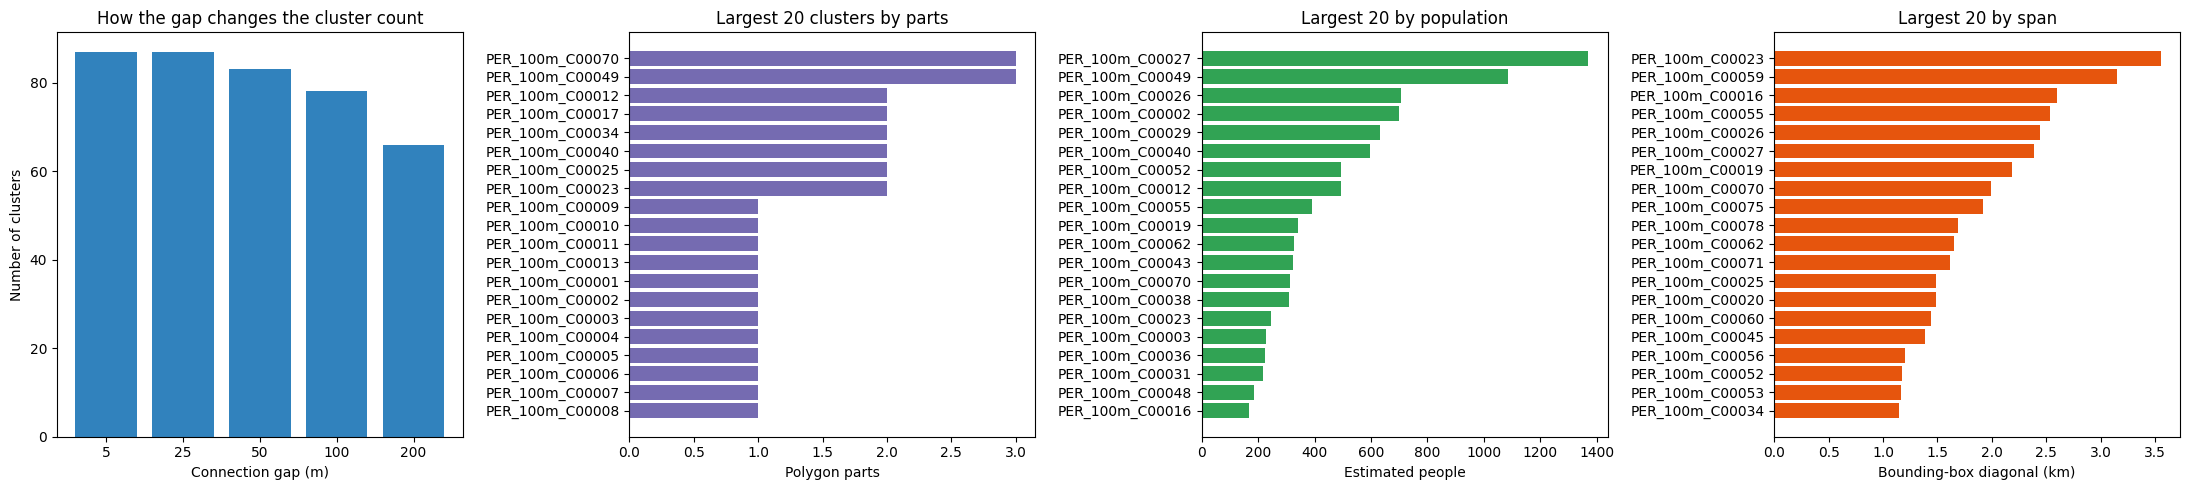

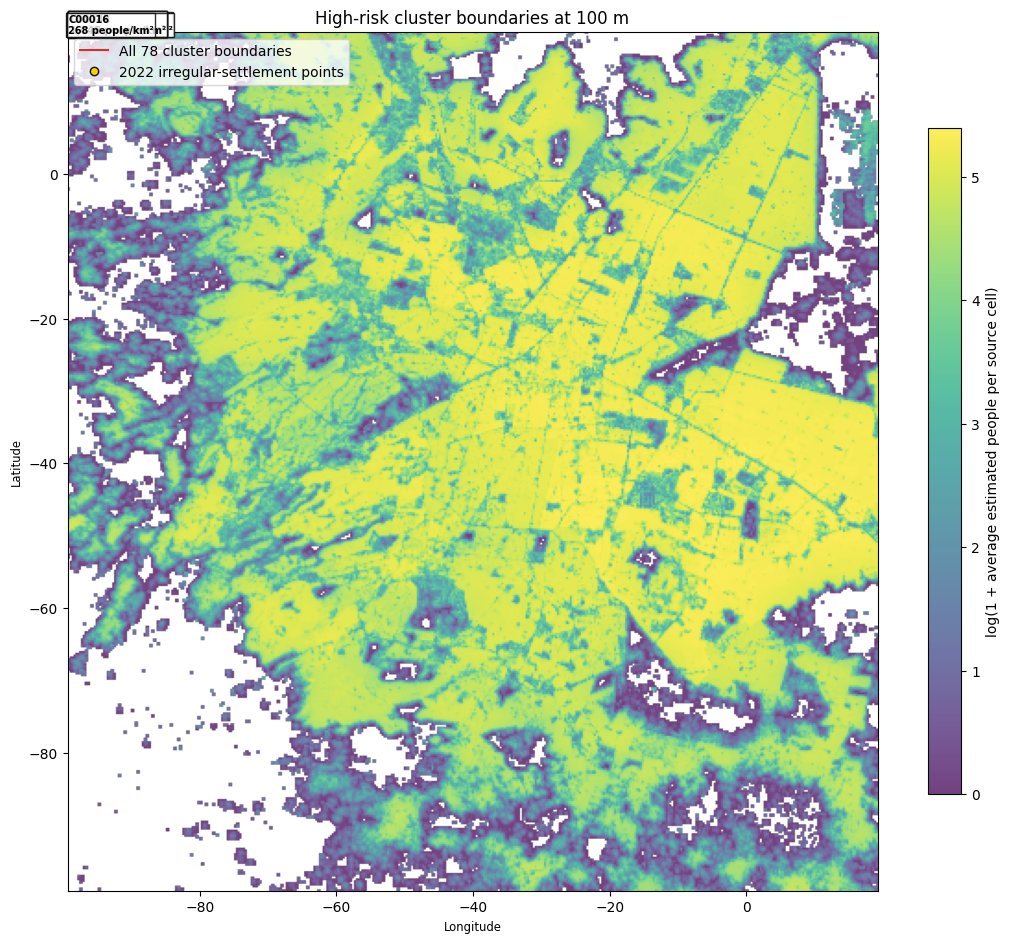

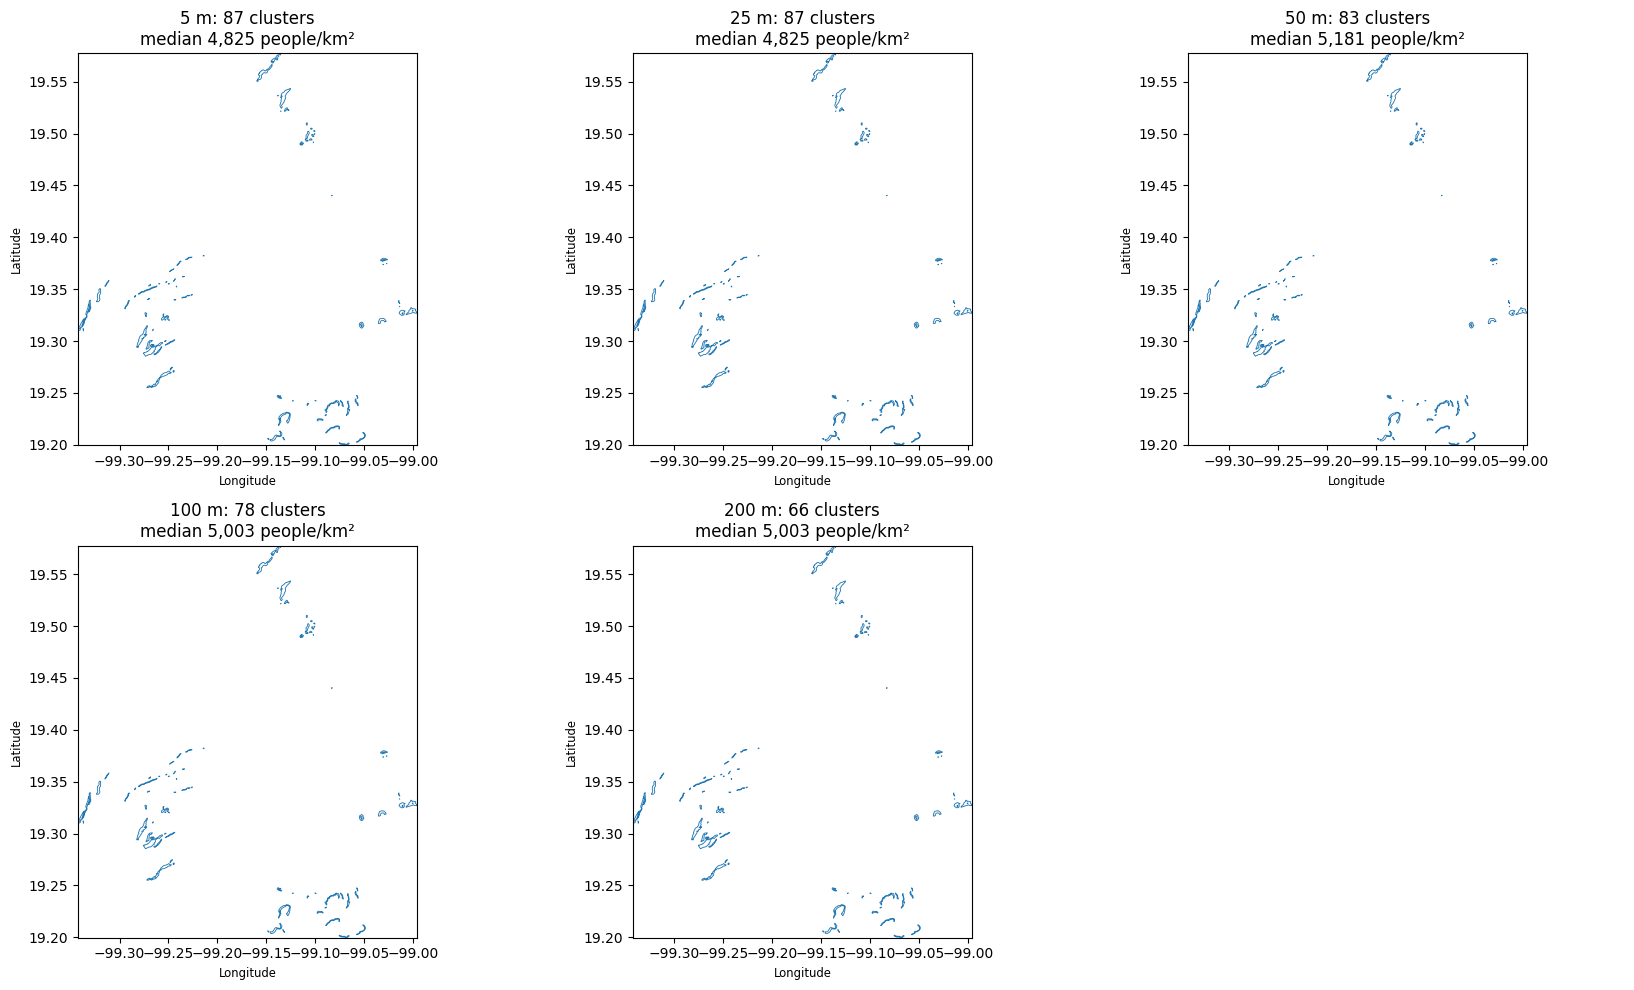

In [20]:
def raster_preview(ax, metric_bounds, max_side=950):
    '''Read only a bounded, downsampled raster window for a map preview.'''
    metric_box = gpd.GeoSeries([box(*metric_bounds)], crs=METRIC_CRS)
    left, bottom, right, top = metric_box.to_crs(raster_crs).total_bounds
    with rasterio.open(RASTER_PATH) as raster:
        window = from_bounds(left, bottom, right, top, raster.transform)
        window = window.intersection(Window(0, 0, raster.width, raster.height))
        width, height = max(1, round(window.width)), max(1, round(window.height))
        scale = min(1, max_side / max(width, height))
        out_shape = (max(1, round(height * scale)), max(1, round(width * scale)))
        image = raster.read(1, window=window, out_shape=out_shape,
                            resampling=Resampling.average, masked=True)
        extent = window_bounds(window, raster.transform)
    # Log colour scaling keeps both sparse and dense cells visible.
    image = np.log1p(np.ma.maximum(image, 0))
    return ax.imshow(image, extent=extent, origin='upper', cmap='viridis', alpha=0.75)

# These figures run before the site draw, including when requested counts are infeasible.
scenario = clusters[clusters.cluster_gap_m.eq(DRAW_CLUSTER_GAP_M)].copy()
scenario_wgs84 = scenario.to_crs(4326)
source_wgs84 = eligible_polygons.to_crs(4326)
print(f'Source features: {source_feature_count:,}; multipart: {multipart_feature_count:,}')
print(f'Individual polygon parts: {len(polygons):,}; screen-eligible: {len(eligible_polygons):,}')
print(f'Clusters with 2022 settlement points at {DRAW_CLUSTER_GAP_M} m: '
      f'{int(scenario.ahi_point_count.gt(0).sum()):,}')
print(f'Clusters at {DRAW_CLUSTER_GAP_M} m: {len(scenario):,}')
print(f'Clusters with bounding-box diagonal over 1 km: '
      f'{int(scenario.cluster_bbox_diagonal_m.gt(1000).sum()):,}')
display(scenario.drop(columns='geometry')[[
    'cluster_id', 'district_names', 'GM_2020', 'IM_2020', 'risk_polygon_count', 'source_feature_count', 'ahi_point_count',
    'cluster_population_estimate', 'cluster_area_km2',
    'cluster_density_people_km2', 'cluster_bbox_width_m',
    'cluster_bbox_height_m', 'cluster_bbox_diagonal_m',
]].sort_values('cluster_bbox_diagonal_m', ascending=False).head(30))

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
gap_counts = clusters.groupby('cluster_gap_m').size().reindex(CLUSTER_GAPS_M)
axes[0].bar([str(gap) for gap in CLUSTER_GAPS_M], gap_counts.values, color='#3182bd')
axes[0].set(xlabel='Connection gap (m)', ylabel='Number of clusters',
            title='How the gap changes the cluster count')
ordered = scenario.nlargest(20, 'risk_polygon_count').sort_values('risk_polygon_count')
axes[1].barh(ordered.cluster_id, ordered.risk_polygon_count, color='#756bb1')
axes[1].set(xlabel='Polygon parts', title='Largest 20 clusters by parts')
ordered_pop = scenario.nlargest(20, 'cluster_population_estimate').sort_values(
    'cluster_population_estimate')
axes[2].barh(ordered_pop.cluster_id, ordered_pop.cluster_population_estimate,
             color='#31a354')
axes[2].set(xlabel='Estimated people', title='Largest 20 by population')
ordered_span = scenario.nlargest(20, 'cluster_bbox_diagonal_m').sort_values(
    'cluster_bbox_diagonal_m')
axes[3].barh(ordered_span.cluster_id, ordered_span.cluster_bbox_diagonal_m / 1000,
             color='#e6550d')
axes[3].set(xlabel='Bounding-box diagonal (km)', title='Largest 20 by span')
plt.tight_layout()
fig.savefig(WORK / 'citywide_cluster_size_diagnostics.png', dpi=180, bbox_inches='tight')
plt.show()

metric_bounds = eligible_polygons.total_bounds
pad_m = 1000
metric_bounds = (metric_bounds[0]-pad_m, metric_bounds[1]-pad_m,
                 metric_bounds[2]+pad_m, metric_bounds[3]+pad_m)
fig, ax = plt.subplots(figsize=(11, 10))
image = raster_preview(ax, metric_bounds)
source_wgs84.boundary.plot(ax=ax, color='#bdbdbd', linewidth=0.2, alpha=0.5)
scenario_wgs84.boundary.plot(ax=ax, color='#de2d26', linewidth=0.7)
if not ahi_visible.empty:
    ahi_visible.to_crs(4326).plot(ax=ax, color='#ffcc00', edgecolor='#111111',
                                markersize=25, zorder=4)
for row in scenario_wgs84.nlargest(
        min(20, len(scenario_wgs84)), 'cluster_population_estimate').itertuples(index=False):
    anchor = row.geometry.representative_point()
    ax.text(anchor.x, anchor.y,
            f"{row.cluster_id.rsplit('_', 1)[-1]}\n{row.cluster_density_people_km2:,.0f} people/km²",
            fontsize=7, weight='bold',
            bbox={'facecolor': 'white', 'alpha': 0.8, 'pad': 1})
ax.legend(handles=[Line2D([0], [0], color='#de2d26', lw=1.5,
                          label=f'All {len(scenario_wgs84):,} cluster boundaries'),
                   Line2D([0], [0], marker='o', color='none',
                          markerfacecolor='#ffcc00', markeredgecolor='#111111',
                          label='2022 irregular-settlement points')],
          loc='upper left')
fig.colorbar(image, ax=ax, shrink=0.7,
             label='log(1 + average estimated people per source cell)')
ax.set(title=f'High-risk cluster boundaries at {DRAW_CLUSTER_GAP_M} m',
       xlabel='Longitude', ylabel='Latitude')
plt.tight_layout()
fig.savefig(WORK / 'citywide_cluster_map_before_draw.png', dpi=180, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(17, 10), squeeze=False)
display_bounds = clusters.to_crs(4326).total_bounds
for ax, gap in zip(axes.flat, CLUSTER_GAPS_M):
    gap_ids = set(membership.loc[
        membership.cluster_gap_m.eq(gap), 'risk_polygon_id'
    ])
    eligible_polygons[eligible_polygons.risk_polygon_id.isin(gap_ids)].to_crs(4326).boundary.plot(
        ax=ax, color='#d0d0d0', linewidth=0.25
    )
    one_gap = clusters[clusters.cluster_gap_m.eq(gap)].to_crs(4326)
    one_gap.boundary.plot(ax=ax, color='#1f78b4', linewidth=0.6)
    ax.set(title=(f'{gap} m: {len(one_gap)} clusters\n'
                  f'median {one_gap.cluster_density_people_km2.median():,.0f} people/km²'),
           xlabel='Longitude', ylabel='Latitude')
    ax.set_xlim(display_bounds[0], display_bounds[2])
    ax.set_ylim(display_bounds[1], display_bounds[3])
for ax in list(axes.flat)[len(CLUSTER_GAPS_M):]:
    ax.axis('off')
plt.tight_layout()
fig.savefig(WORK / 'citywide_cluster_gap_comparison.png', dpi=180, bbox_inches='tight')
plt.show()


## 5. Survey planning: power and precision side by side

This section runs before the random draw. It contains one planning code cell directly below, with three clearly marked parts:

1. **Inputs and assumptions**: set `CONFIDENCE_LEVEL`, the target margin of error, the effect used for power, candidate sample sizes, and cluster-variation scenarios. The default is **90% confidence**, **±5 percentage points** for the inside–outside survey difference, and an 80% reference line for power.
2. **Power calculation**: for each candidate design, it simulates the chance of detecting the prespecified 10-point inside–outside difference at the configured two-sided significance level. It reports all power levels; 80% is not imposed as a requirement.
3. **Precision calculation**: from the same simulations, it calculates the achieved 90% margin of error for the inside–outside difference and the share of simulated datasets that meet the ±5-point target.

The results run **without pilot first**, using assumed outside response rates, then **with pilot** if `pilot_results.xlsx` is available. The ±5-point target concerns the estimated difference between inside and outside, not each rate separately. Cluster variation is separate from confidence level: it allows the true inside–outside difference to vary across sites.


In [ ]:
# Manual cluster exclusions are part of the eligible draw frame. Review IDs
# whenever the source, screening thresholds, or cluster gap changes.
EXCLUDED_CLUSTER_IDS = ['PER_100m_C00001','PER_100m_C00004','PER_100m_C00008','PER_100m_C00014','PER_100m_C00015','PER_100m_C00018','PER_100m_C00019','PER_100m_C00022','PER_100m_C00023',
                        'PER_100m_C00024','PER_100m_C00026','PER_100m_C00027','PER_100m_C00028','PER_100m_C00029','PER_100m_C00032','PER_100m_C00033','PER_100m_C00036','PER_100m_C00037',
                        'PER_100m_C00038','PER_100m_C00039','PER_100m_C00040','PER_100m_C00041','PER_100m_C00042','PER_100m_C00045','PER_100m_C00046','PER_100m_C00047','PER_100m_C00048',
                        'PER_100m_C00050','PER_100m_C00053','PER_100m_C00054','PER_100m_C00056','PER_100m_C00060','PER_100m_C00061','PER_100m_C00062','PER_100m_C00063','PER_100m_C00064',
                        'PER_100m_C00065','PER_100m_C00066','PER_100m_C00067','PER_100m_C00068','PER_100m_C00069','PER_100m_C00070','PER_100m_C00071','PER_100m_C00072','PER_100m_C00073',
                        'PER_100m_C00077','PER_100m_C00078']  # e.g. ['PER_005m_C00003']

# Survey responses in the survey tab of pilot_results; uppercase codes and
# blank or ? answers are normalized by the loader. Keep a respondent audit.
PILOT_BOUNDARY_COLUMN = 'boundary _id'  # source header includes a space
PILOT_SIDE_COLUMN = 'boundary_side'
PILOT_MOVING_COLUMN = 'considered_moving'
PILOT_INSIDE_VALUE = 'INSIDE'
PILOT_OUTSIDE_VALUE = 'OUTSIDE'
PILOT_YES_VALUES = ('yes', 'si', 'sí', '1', 'true')
PILOT_NO_VALUES = ('no', '0', 'false')

INTERVIEW_TOTALS = (200, 300, 400, 600, 800, 1000)
PRIMARY_CLUSTER_OPTIONS = (8, 12, 16, 20)
SURVEY_DIFFERENCE = 0.10  # absolute 10-percentage-point inside minus outside
OUTSIDE_PREVALENCE_SCENARIOS = (0.20, 0.50)
SURVEY_CLUSTER_DIFFERENCE_SD_SCENARIOS = (0.00, 0.05, 0.10)  # 0 = no cluster variation
# Statistical planning settings. The confidence level determines the two-sided
# alpha threshold used by the power calculation and the precision interval.
CONFIDENCE_LEVEL = 0.90
SURVEY_TARGET_MARGIN_OF_ERROR = 0.05  # ±5 percentage points for the difference
POWER_TARGET = 0.80  # a reference line; the full power curve is reported
POWER_REPLICATIONS = 2000
POWER_SEED = 20261111
SITE_USABILITY_SCENARIOS = (0.70, 0.80, 0.90)
RESERVE_COVERAGE_TARGET = 0.90
if not 0 < CONFIDENCE_LEVEL < 1:
    raise ValueError('CONFIDENCE_LEVEL must be strictly between 0 and 1.')
if not 0 < SURVEY_TARGET_MARGIN_OF_ERROR < 1:
    raise ValueError('SURVEY_TARGET_MARGIN_OF_ERROR must be between 0 and 1.')
ALPHA_TWO_SIDED = 1 - CONFIDENCE_LEVEL
# Empirical results from the verified twelve-card DCE simulation in
# Survey/dce_power/Power findings.md (moderate baseline, focused model,
# inside × Relocate-versus-Stay OR 1.5). No site-level variation was modeled.
DCE_REFERENCE_POWER = {
    'moderate': {200: 0.552, 300: 0.664, 400: 0.812},
    'relocation_averse': {200: 0.312, 300: 0.436, 400: 0.520},
    'respondent_heterogeneity': {200: 0.392, 300: 0.604, 400: 0.708},
}

def load_pilot_outside_rate():
    """Summarize observed survey answers and return the outside yes rate."""
    pilot = pilot_tab(PILOT_SURVEY_TAB)
    if pilot is None:
        return None
    required = {PILOT_BOUNDARY_COLUMN, PILOT_SIDE_COLUMN, PILOT_MOVING_COLUMN}
    if not required.issubset(pilot.columns):
        raise ValueError(f'Survey pilot tab is missing: {sorted(required - set(pilot.columns))}')
    pilot['_side'] = pilot[PILOT_SIDE_COLUMN].astype(str).str.strip().str.casefold()
    inside, outside = PILOT_INSIDE_VALUE.casefold(), PILOT_OUTSIDE_VALUE.casefold()
    if not pilot['_side'].isin([inside, outside]).all():
        raise ValueError('Survey pilot side codes differ from INSIDE/OUTSIDE.')
    answer = pilot[PILOT_MOVING_COLUMN].astype(str).str.strip().str.casefold()
    yes, no = set(PILOT_YES_VALUES), set(PILOT_NO_VALUES)
    unknown = set(answer.unique()) - yes - no - {'', '?', 'unsure', 'no sabe'}
    if unknown:
        raise ValueError(f'Unexpected survey pilot answers: {sorted(unknown)}')
    pilot['_yes'] = answer.map(lambda value: 1 if value in yes else (0 if value in no else np.nan))
    pilot_summary = pilot.groupby([PILOT_BOUNDARY_COLUMN, '_side']).agg(
        records=('_side', 'size'), answered=('_yes', 'count'),
        yes=('_yes', 'sum'), yes_rate=('_yes', 'mean')).reset_index()
    pilot_summary['unknown'] = pilot_summary.records - pilot_summary.answered
    display(pilot_summary)
    pilot_summary.to_csv(WORK / 'citywide_survey_pilot_summary.csv', index=False)
    outside_answers = pilot.loc[pilot._side.eq(outside), '_yes'].dropna()
    if outside_answers.empty:
        raise ValueError('Survey pilot has no answered outside responses.')
    return float(outside_answers.mean())

pilot_outside_rate = load_pilot_outside_rate()
# Keep assumed baselines and the observed pilot baseline in separate outputs.
survey_baselines = [('without_pilot_20pct', 0.20), ('without_pilot_50pct', 0.50)]
if pilot_outside_rate is not None:
    survey_baselines.append(('with_pilot', pilot_outside_rate))
if not all(0 < rate < 1 - SURVEY_DIFFERENCE for _, rate in survey_baselines):
    raise ValueError('Every outside prevalence must allow the chosen 10-point increase.')

def survey_power_simulation(n_total, cluster_count, p_out, site_diff_sd, seed):
    '''Simulate binary responses and test paired cluster-side differences.'''
    rng = np.random.default_rng(seed)
    inside_total = n_total // 2
    outside_total = n_total - inside_total
    # Distribute each side's completed interviews as evenly as possible.
    inside_n = np.array([inside_total // cluster_count + (j < inside_total % cluster_count)
                         for j in range(cluster_count)])
    outside_n = np.array([outside_total // cluster_count + (j < outside_total % cluster_count)
                          for j in range(cluster_count)])
    true_diff = rng.normal(SURVEY_DIFFERENCE, site_diff_sd,
                           size=(POWER_REPLICATIONS, cluster_count))
    p_inside = np.clip(p_out + true_diff, 0.001, 0.999)
    inside_yes = rng.binomial(inside_n, p_inside)
    outside_yes = rng.binomial(outside_n, p_out,
                              size=(POWER_REPLICATIONS, cluster_count))
    differences = inside_yes / inside_n - outside_yes / outside_n
    mean_diff = differences.mean(axis=1)
    se = differences.std(axis=1, ddof=1) / np.sqrt(cluster_count)
    critical = student_t.ppf(1 - ALPHA_TWO_SIDED / 2, df=cluster_count - 1)
    detected = np.abs(np.divide(mean_diff, se, out=np.zeros_like(mean_diff), where=se > 0)) > critical
    power = float(detected.mean())
    margin_of_error = critical * se
    return (power, float(np.sqrt(power * (1 - power) / POWER_REPLICATIONS)),
            float(np.nanmedian(margin_of_error)),
            float(np.nanpercentile(margin_of_error, 90)),
            float(np.mean(margin_of_error <= SURVEY_TARGET_MARGIN_OF_ERROR)))

def independent_survey_minimum(p_out):
    '''Lower-bound total N for 80% power with independent balanced responses.'''
    p_in = p_out + SURVEY_DIFFERENCE
    z_alpha, z_target = norm.ppf(1 - ALPHA_TWO_SIDED / 2), norm.ppf(POWER_TARGET)
    pooled = (p_out + p_in) / 2
    n_per_side = ((z_alpha * np.sqrt(2 * pooled * (1 - pooled)) +
                   z_target * np.sqrt(p_out * (1 - p_out) + p_in * (1 - p_in))) /
                  SURVEY_DIFFERENCE) ** 2
    return 2 * int(np.ceil(n_per_side))

def independent_precision_minimum(p_out):
    # Lower-bound total N for target difference margin of error, ignoring clusters.
    p_in = p_out + SURVEY_DIFFERENCE
    z = norm.ppf(1 - ALPHA_TWO_SIDED / 2)
    n_per_side = z**2 * (p_out * (1-p_out) + p_in * (1-p_in)) / SURVEY_TARGET_MARGIN_OF_ERROR**2
    return 2 * int(np.ceil(n_per_side))

survey_records = []
for baseline_source, p_out in survey_baselines:
    for n_total in INTERVIEW_TOTALS:
        for cluster_count in PRIMARY_CLUSTER_OPTIONS:
            for site_sd in SURVEY_CLUSTER_DIFFERENCE_SD_SCENARIOS:
                # Stable distinct seeds preserve reproducibility when the
                # pilot baseline or loop order changes.
                seed = (POWER_SEED + int(p_out * 10000) * 100000 +
                        n_total * 100 + cluster_count * 10 + int(site_sd * 100))
                (power, mc_se, median_moe, p90_moe, share_meeting_moe) = survey_power_simulation(
                    n_total, cluster_count, p_out, site_sd, seed)
                survey_records.append({
                    'baseline_source': baseline_source,
                    'outside_prevalence': p_out,
                    'completed_interviews': n_total,
                    'primary_clusters': cluster_count,
                    'completed_per_side_per_cluster': n_total / (2 * cluster_count),
                    'cluster_difference_sd': site_sd,
                    'cluster_variation': 'none' if site_sd == 0 else 'assumed',
                    'survey_power': power,
                    'survey_power_mc_se': mc_se,
                    'confidence_level': CONFIDENCE_LEVEL,
                    'two_sided_alpha': ALPHA_TWO_SIDED,
                    'target_margin_of_error': SURVEY_TARGET_MARGIN_OF_ERROR,
                    'median_margin_of_error': median_moe,
                    'p90_margin_of_error': p90_moe,
                    'share_simulations_meeting_moe_target': share_meeting_moe,
                    'meets_80pct_target': power >= POWER_TARGET,
                    'majority_meet_moe_target': share_meeting_moe >= 0.50,
                })
allocation_power = pd.DataFrame(survey_records)
allocation_power.to_csv(WORK / 'citywide_sampling_allocation_power_sensitivity.csv', index=False)

def show_survey_scenarios(frame, label, filename):
    """Save and display power and precision for the exact same simulations."""
    frame.to_csv(WORK / filename, index=False)
    print(f'{label}: {CONFIDENCE_LEVEL:.0%} confidence; two-sided alpha {ALPHA_TWO_SIDED:.0%}; '
          f'precision target ±{SURVEY_TARGET_MARGIN_OF_ERROR:.0%}.')
    rates = frame[['baseline_source', 'outside_prevalence']].drop_duplicates().copy()
    rates['independent_n_for_80pct_power'] = rates.outside_prevalence.map(independent_survey_minimum)
    rates['independent_n_for_target_moe'] = rates.outside_prevalence.map(independent_precision_minimum)
    print('Independent-response lower bounds, which omit cluster variation:')
    display(rates.round(3))
    comparison = frame[['baseline_source', 'completed_interviews', 'primary_clusters',
                        'cluster_difference_sd', 'survey_power', 'survey_power_mc_se',
                        'median_margin_of_error', 'p90_margin_of_error',
                        'share_simulations_meeting_moe_target']]
    print('Same simulated designs: power and achieved precision side by side:')
    display(comparison.round(3))
    for baseline_source, group in frame.groupby('baseline_source', sort=False):
        fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex='col')
        for col, sd in enumerate(SURVEY_CLUSTER_DIFFERENCE_SD_SCENARIOS[:2]):
            subset = group.loc[group.cluster_difference_sd.eq(sd)]
            for k, series in subset.groupby('primary_clusters'):
                axes[0, col].plot(series.completed_interviews, series.survey_power,
                                  marker='o', label=f'{k} clusters')
                axes[1, col].plot(series.completed_interviews, series.median_margin_of_error,
                                  marker='o', label=f'{k} clusters')
            axes[0, col].axhline(POWER_TARGET, color='black', linestyle='--', linewidth=1)
            axes[1, col].axhline(SURVEY_TARGET_MARGIN_OF_ERROR, color='black', linestyle='--', linewidth=1)
            axes[0, col].set_title(f'Cluster-effect SD = {sd:.2f}')
            axes[1, col].set_xlabel('Completed interviews')
            axes[0, col].grid(alpha=0.2)
            axes[1, col].grid(alpha=0.2)
        axes[0, 0].set_ylabel('Power for 10-point difference')
        axes[1, 0].set_ylabel(f'Median {CONFIDENCE_LEVEL:.0%} margin of error')
        axes[0, 1].legend(title=baseline_source, fontsize=8)
        fig.tight_layout()
        display(fig)
        plt.close(fig)

without_pilot_survey = allocation_power.loc[
    allocation_power.baseline_source.str.startswith('without_pilot')].copy()
show_survey_scenarios(without_pilot_survey, 'WITHOUT PILOT',
                      'citywide_survey_power_without_pilot.csv')
if pilot_outside_rate is not None:
    with_pilot_survey = allocation_power.loc[
        allocation_power.baseline_source.eq('with_pilot')].copy()
    show_survey_scenarios(with_pilot_survey, 'WITH SURVEY PILOT',
                          'citywide_survey_power_with_pilot.csv')
else:
    print('WITH SURVEY PILOT: skipped because no pilot workbook is configured.')
print('A design may meet the power reference, the precision target, both, or neither. Missing combinations did not meet the power reference by the largest tested N.')
display(allocation_power.loc[allocation_power.meets_80pct_target].groupby(
    ['baseline_source', 'primary_clusters', 'cluster_difference_sd'], as_index=False
).completed_interviews.min())

# Reserve counts concern later site usability, not statistical power. Each
# scenario assumes independent cluster usability with the stated probability.
reserve_rows = []
for k in PRIMARY_CLUSTER_OPTIONS:
    for usable_probability in SITE_USABILITY_SCENARIOS:
        r = next(r for r in range(0, 101)
                 if binom.sf(k - 1, k + r, usable_probability) >= RESERVE_COVERAGE_TARGET)
        reserve_rows.append({'primary_clusters': k, 'site_usable_probability': usable_probability,
                             'reserves_for_90pct_coverage': r,
                             'total_random_order_needed': k + r})
reserve_plan = pd.DataFrame(reserve_rows)
draw_ids = set(clusters.loc[clusters.cluster_gap_m.eq(DRAW_CLUSTER_GAP_M), 'cluster_id'])
unknown_draw_ids = set(EXCLUDED_CLUSTER_IDS) - draw_ids
if unknown_draw_ids:
    raise ValueError(f'Manual exclusion IDs not found at the selected gap: {sorted(unknown_draw_ids)}')
available_draw_clusters = len(draw_ids) - len(set(EXCLUDED_CLUSTER_IDS))
reserve_plan['fits_current_draw_frame'] = reserve_plan.total_random_order_needed.le(available_draw_clusters)
print(f'Current draw-gap clusters: {len(draw_ids)}; manually excluded: {len(EXCLUDED_CLUSTER_IDS)}; available: {available_draw_clusters}')
reserve_plan.to_csv(WORK / 'citywide_sampling_reserve_sensitivity.csv', index=False)
print('Reserve sensitivity (assumed independent chance each drawn site is usable):')
display(reserve_plan)
print('These scenarios are planning inputs, not a final sample-size or reserve recommendation.')


## 5a. Compare DCE power without and with the pilot

First, the notebook prints the earlier **verified choice-level simulation without the pilot**. Its three scenarios (moderate, relocation-averse, respondent heterogeneity) cover 200, 300, and 400 completed respondents and assume no between-cluster variation. The next table and maps add a **Gaussian Monte Carlo sensitivity approximation** for the hypothetical moderate and relocation-averse baselines at 200–1,000 respondents, 8–20 clusters, and assumed standard deviations of the cluster-specific inside × Relocate log-odds effect of **0, 0.25, and 0.50**. Zero means no variation. Edit `DCE_CLUSTER_LOG_OR_SD_SCENARIOS` in this section to change those assumptions. They are not estimates from the pilot. The new approximate DCE calculations use the same editable 90% confidence setting from Section 5; the earlier verified results remain historical 95% benchmarks. The sensitivity calculation treats each assumed standard deviation as known, so its power can be optimistic when the true variation is uncertain.

Then, the `DCE` tab of the `pilot_results.xlsx` snapshot supplies one row per respondent × card. Uppercase choices are normalized; `?` block/task codes and `NONE` or `?` choices are audited. The model uses only respondents with four identified, answered cards, while descriptive choice shares also use known answers on rows with unknown card IDs. A weakly regularized pooled eight-coefficient model estimates baseline choice tendencies. It does **not** estimate the inside effect or cluster variation from the two pilot boundaries. The same Gaussian sensitivity calculation uses this pilot baseline, the prespecified odds ratio of **1.5**, and the three cluster-variation assumptions.

The Gaussian approximation uses the focused ten-term DCE model's expected information for independent choices, then adds variation in the cluster-specific inside effect. It does not simulate the full four-choice response process, fit a cluster-robust model, or account for other respondent-level heterogeneity. Read it beside the earlier choice-level results, especially when choosing a final sample size. Export a fresh Excel copy of the live pilot Sheet whenever responses change; the workbook in mounted Drive does not synchronize automatically.


In [ ]:
# DCE tab in the same Excel pilot snapshot. Unknown card codes and unanswered
# choices are audited below; only complete, identified four-card sets enter fit.
DCE_RESPONDENT_COLUMN = 'respondent_id'
DCE_BOUNDARY_COLUMN = 'boundary_id'
DCE_SIDE_COLUMN = 'boundary_side'
DCE_BLOCK_COLUMN = 'block'
DCE_TASK_COLUMN = 'task'
DCE_CHOICE_COLUMN = 'choice'
DCE_INSIDE_VALUE = 'inside'
DCE_OUTSIDE_VALUE = 'outside'
DCE_CHOICE_CODES = {'stay': 0, 'protect': 1, 'relocate': 2}

# Card attributes verified against the twelve-card DCE design. Each tuple is
# (block, task, stay severe, protect usable, protect grant 50%, relocate
# grant 520k, relocate credit, relocate in another alcaldia).
DCE_CARD_ROWS = [
    ('A', 1, 1, 1, 1, 1, 0, 0), ('A', 2, 0, 1, 0, 0, 0, 0),
    ('A', 3, 1, 0, 0, 0, 1, 1), ('A', 4, 1, 0, 1, 0, 0, 1),
    ('B', 1, 1, 1, 1, 0, 0, 1), ('B', 2, 0, 1, 1, 0, 1, 0),
    ('B', 3, 1, 1, 0, 1, 0, 1), ('B', 4, 1, 0, 0, 0, 1, 0),
    ('C', 1, 1, 1, 0, 0, 0, 0), ('C', 2, 1, 0, 1, 1, 0, 0),
    ('C', 3, 0, 1, 0, 1, 0, 1), ('C', 4, 0, 1, 1, 0, 1, 1),
]
DCE_BASE_NAMES = ['ASC_protect', 'ASC_relocate', 'stay_severe',
                  'protect_usable', 'protect_grant50', 'relocate_grant520k',
                  'relocate_credit', 'relocate_other_alcaldia']

def dce_card_matrix():
    '''Encode Stay, Protect, Relocate for each verified block and task.'''
    designs = {}
    for block, task, severe, usable, protect_grant, relocation_grant, credit, other in DCE_CARD_ROWS:
        designs[(block, task)] = np.array([
            [0, 0, severe, 0, 0, 0, 0, 0],
            [1, 0, 0, usable, protect_grant, 0, 0, 0],
            [0, 1, 0, 0, 0, relocation_grant, credit, other],
        ], dtype=float)
    if len(designs) != 12:
        raise AssertionError('The DCE design must contain 12 distinct cards.')
    return designs

def load_dce_pilot():
    """Audit raw pilot cards, summarize choices, and retain complete respondents."""
    pilot = pilot_tab(PILOT_DCE_TAB)
    if pilot is None:
        print('DCE pilot sheet not configured; using hypothetical reference scenarios only.')
        return None
    columns = [DCE_RESPONDENT_COLUMN, DCE_BOUNDARY_COLUMN, DCE_SIDE_COLUMN,
               DCE_BLOCK_COLUMN, DCE_TASK_COLUMN, DCE_CHOICE_COLUMN]
    absent = set(columns) - set(pilot.columns)
    if absent:
        raise ValueError(f'DCE pilot tab is missing columns: {sorted(absent)}')
    pilot['_block'] = pilot[DCE_BLOCK_COLUMN].astype(str).str.strip().str.upper()
    pilot['_task'] = pd.to_numeric(pilot[DCE_TASK_COLUMN], errors='coerce')
    pilot['_side'] = pilot[DCE_SIDE_COLUMN].astype(str).str.strip().str.casefold()
    pilot['_choice'] = pilot[DCE_CHOICE_COLUMN].astype(str).str.strip().str.casefold()
    if not pilot['_side'].isin({DCE_INSIDE_VALUE.casefold(), DCE_OUTSIDE_VALUE.casefold()}).all():
        raise ValueError('DCE pilot side codes differ from INSIDE/OUTSIDE.')
    if pilot[DCE_RESPONDENT_COLUMN].astype(str).str.strip().eq('').any():
        raise ValueError('DCE pilot has a blank respondent ID.')
    if pilot[DCE_BOUNDARY_COLUMN].astype(str).str.strip().eq('').any():
        raise ValueError('DCE pilot has a blank boundary ID.')
    invalid_choices = set(pilot._choice.unique()) - set(DCE_CHOICE_CODES) - {'?', '', 'none'}
    if invalid_choices:
        raise ValueError(f'Unexpected DCE choice codes: {sorted(invalid_choices)}')
    cards = dce_card_matrix()
    pilot['_card_known'] = [(block, task) in cards for block, task in zip(pilot._block, pilot._task)]
    pilot['_choice_known'] = pilot._choice.isin(DCE_CHOICE_CODES)
    pilot['_row_usable'] = pilot._card_known & pilot._choice_known
    # Choice shares can use answers even when the card identifier is unknown.
    shares = pilot.loc[pilot._choice_known].groupby(
        [DCE_BOUNDARY_COLUMN, '_side', '_choice']).size().rename('choices').reset_index()
    shares['share'] = shares.choices / shares.groupby(
        [DCE_BOUNDARY_COLUMN, '_side']).choices.transform('sum')
    shares.to_csv(WORK / 'citywide_dce_pilot_choice_shares.csv', index=False)
    display(shares)
    person = pilot.groupby(DCE_RESPONDENT_COLUMN).agg(
        rows=('_row_usable', 'size'), usable_rows=('_row_usable', 'sum'),
        blocks=('_block', 'nunique'), tasks=('_task', 'nunique'),
        sides=('_side', 'nunique'), boundaries=(DCE_BOUNDARY_COLUMN, 'nunique'))
    person['model_included'] = ((person.rows == 4) & (person.usable_rows == 4) &
                                (person.blocks == 1) & (person.tasks == 4) &
                                (person.sides == 1) & (person.boundaries == 1))
    person['reason'] = np.where(person.model_included, 'complete_four_cards',
                                'unknown_or_unanswered_card_or_incomplete_set')
    person.reset_index().to_csv(WORK / 'citywide_dce_pilot_inclusion_audit.csv', index=False)
    print(f'DCE pilot: {len(person)} respondents, {len(pilot)} rows; '
          f'{int(person.model_included.sum())} complete respondents for model. '
          f'Unknown card rows: {int((~pilot._card_known).sum())}; '
          f'unknown/unanswered choices: {int((~pilot._choice_known).sum())}.')
    included_ids = person.index[person.model_included]
    if len(included_ids) < 1:
        raise ValueError('No complete DCE respondent has four identified, answered cards.')
    return pilot.loc[pilot[DCE_RESPONDENT_COLUMN].isin(included_ids)].copy()

# The earlier choice-level empirical simulation is retained as the
# no-pilot, no-cluster-variation benchmark. Its respondent heterogeneity
# scenario is shown here, but not reproduced by the Gaussian approximation.
reference_rows = []
for scenario, powers in DCE_REFERENCE_POWER.items():
    for n_total, power in powers.items():
        reference_rows.append({'baseline_source': scenario,
                               'completed_interviews': n_total,
                               'empirical_dce_power_no_cluster_variation': power})
dce_reference_table = pd.DataFrame(reference_rows)
print('WITHOUT PILOT: earlier verified choice-level DCE simulation, no cluster variation:')
display(dce_reference_table)

DCE_TARGET_ODDS_RATIO = 1.5  # prespecified inside × Relocate-versus-Stay effect
DCE_CLUSTER_LOG_OR_SD_SCENARIOS = (0.0, 0.25, 0.50)  # assumed; 0 means none
DCE_POWER_REPLICATIONS = 20000
DCE_POWER_SEED = POWER_SEED + 700000
DCE_RIDGE_STRENGTH = 1.0  # fixed weak shrinkage for a small pilot
DCE_ASSUMED_BASELINES = {
    'moderate': np.array([-0.4, -0.7, -0.8, 0.5, 0.4, 0.4, 0.1, -0.4]),
    'relocation_averse': np.array([-0.2, -1.5, -1.2, 0.8, 0.5, 0.5, 0.0, -0.7]),
}
cards = dce_card_matrix()

def expected_dce_se(n_total, baseline):
    """Focused-model information SE under balanced sides and card blocks."""
    effect = np.log(DCE_TARGET_ODDS_RATIO)
    beta = np.r_[baseline, 0.0, effect]  # inside Protect and Relocate ASCs
    information = np.zeros((10, 10))
    for side in (0, 1):
        for block in 'ABC':
            for task in (1, 2, 3, 4):
                base = cards[(block, task)]
                x = np.column_stack((base, side * base[:, :2]))
                utility = x @ beta
                probabilities = np.exp(utility - np.logaddexp.reduce(utility))
                centered = x - probabilities @ x
                information += (n_total / 6) * ((probabilities[:, None] * centered).T @ centered)
    if np.linalg.matrix_rank(information) < 10:
        raise ValueError('DCE focused-model information matrix is singular.')
    return float(np.sqrt(np.linalg.inv(information)[9, 9]))

def dce_cluster_power_simulation(n_total, cluster_count, baseline, cluster_log_or_sd, seed):
    """Gaussian Monte Carlo sensitivity for the site-varying DCE effect.

    The independent-choice information SE approximates respondent sampling
    error. The mean of cluster-specific effects adds SD/sqrt(K) uncertainty.
    This is not a choice-level simulation or a cluster-robust model fit.
    """
    rng = np.random.default_rng(seed)
    effect = np.log(DCE_TARGET_ODDS_RATIO)
    information_se = expected_dce_se(n_total, baseline)
    site_means = rng.normal(0, cluster_log_or_sd,
                            size=(DCE_POWER_REPLICATIONS, cluster_count)).mean(axis=1)
    sampling_error = rng.normal(0, information_se, DCE_POWER_REPLICATIONS)
    estimate = effect + site_means + sampling_error
    assumed_se = np.sqrt(information_se**2 + cluster_log_or_sd**2 / cluster_count)
    critical = norm.ppf(1 - ALPHA_TWO_SIDED / 2)
    detected = np.abs(estimate / assumed_se) > critical
    power = float(detected.mean())
    return power, float(np.sqrt(power * (1-power) / DCE_POWER_REPLICATIONS)), information_se

def dce_sensitivity_frame(baselines, label):
    """Run each baseline across totals, clusters, and cluster-effect SDs."""
    rows = []
    for baseline_index, (name, baseline) in enumerate(baselines.items()):
        for n_total in INTERVIEW_TOTALS:
            for k in PRIMARY_CLUSTER_OPTIONS:
                for sd in DCE_CLUSTER_LOG_OR_SD_SCENARIOS:
                    seed = (DCE_POWER_SEED + baseline_index * 100000 +
                            n_total * 100 + k * 10 + int(sd * 100))
                    power, mc_se, information_se = dce_cluster_power_simulation(
                        n_total, k, baseline, sd, seed)
                    rows.append({'baseline_source': name,
                                 'completed_interviews': n_total,
                                 'primary_clusters': k,
                                 'completed_per_side_per_cluster': n_total / (2*k),
                                 'cluster_log_or_sd': sd,
                                 'cluster_variation': 'none' if sd == 0 else 'assumed',
                                 'target_odds_ratio': DCE_TARGET_ODDS_RATIO,
                                 'confidence_level': CONFIDENCE_LEVEL,
                                 'two_sided_alpha': ALPHA_TWO_SIDED,
                                 'dce_power_approx': power,
                                 'dce_power_mc_se': mc_se,
                                 'independent_choice_information_se': information_se,
                                 'meets_80pct_target': power >= POWER_TARGET})
    frame = pd.DataFrame(rows)
    frame.to_csv(WORK / f'citywide_dce_power_{label}.csv', index=False)
    print(f'{label.upper().replace("_", " ")}: approximate DCE power, zero and assumed between-cluster variation:')
    display(frame[['baseline_source', 'completed_interviews', 'primary_clusters',
                   'cluster_log_or_sd', 'dce_power_approx', 'dce_power_mc_se']].round(3))
    for name, group in frame.groupby('baseline_source', sort=False):
        fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
        for ax, sd in zip(axes, DCE_CLUSTER_LOG_OR_SD_SCENARIOS[:2]):
            subset = group.loc[group.cluster_log_or_sd.eq(sd)]
            for k, series in subset.groupby('primary_clusters'):
                ax.plot(series.completed_interviews, series.dce_power_approx,
                        marker='o', label=f'{k} clusters')
            ax.axhline(POWER_TARGET, color='black', linestyle='--', linewidth=1)
            ax.set(title=f'Cluster-effect SD = {sd:.2f}', xlabel='Completed interviews', ylim=(0, 1))
            ax.grid(alpha=0.2)
        axes[0].set_ylabel('Approximate DCE power for OR 1.5')
        axes[1].legend(title=name, fontsize=8)
        fig.tight_layout()
        display(fig)
        plt.close(fig)
    return frame

without_pilot_dce = dce_sensitivity_frame(DCE_ASSUMED_BASELINES, 'without_pilot')

# The 12 complete respondents in the present two-boundary pilot inform only
# the pooled baseline choice coefficients. The target effect and cluster SD
# remain prespecified planning inputs.
dce_pilot = load_dce_pilot()
if dce_pilot is not None:
    from scipy.optimize import minimize
    from scipy.special import logsumexp
    pilot_x = np.stack([cards[(b, t)] for b, t in zip(dce_pilot._block, dce_pilot._task)])
    pilot_y = dce_pilot._choice.map(DCE_CHOICE_CODES).to_numpy(dtype=int)
    picked = pilot_x[np.arange(len(pilot_x)), pilot_y]

    def pilot_objective(beta):
        """Penalized conditional-choice likelihood for eight baseline terms."""
        utility = np.einsum('nap,p->na', pilot_x, beta)
        probabilities = np.exp(utility - logsumexp(utility, axis=1, keepdims=True))
        loss = float(logsumexp(utility, axis=1).sum() - picked.sum(axis=0) @ beta +
                     DCE_RIDGE_STRENGTH * (beta @ beta) / 2)
        gradient = (np.einsum('na,nap->p', probabilities, pilot_x) -
                    picked.sum(axis=0) + DCE_RIDGE_STRENGTH * beta)
        return loss, gradient

    fitted = minimize(pilot_objective, np.zeros(8), jac=True, method='BFGS',
                      options={'maxiter': 1000, 'gtol': 1e-6})
    if not np.all(np.isfinite(fitted.x)) or np.max(np.abs(pilot_objective(fitted.x)[1])) > 1e-3:
        raise RuntimeError('DCE pilot baseline fit did not reach a usable solution.')
    dce_baseline = fitted.x
    fit_table = pd.DataFrame({'coefficient': DCE_BASE_NAMES, 'pilot_ridge_estimate': dce_baseline})
    fit_table.to_csv(WORK / 'citywide_dce_pilot_baseline_coefficients.csv', index=False)
    print('WITH PILOT: pooled baseline coefficients with ridge shrinkage:')
    display(fit_table.round(3))
    with_pilot_dce = dce_sensitivity_frame({'pilot_ridge': dce_baseline}, 'with_pilot')
    # Preserve the earlier no-cluster output name for downstream readers.
    pilot_power = with_pilot_dce.loc[with_pilot_dce.cluster_log_or_sd.eq(0)].copy()
    pilot_power.to_csv(WORK / 'citywide_dce_pilot_calibrated_power.csv', index=False)
    print('These pilot-based DCE curves are planning sensitivities, not final sample-size estimates.')
    print('The two pilot boundaries cannot identify citywide cluster-effect variation.')
else:
    print('WITH PILOT DCE: skipped because pilot data are unavailable.')


## 6. Order and select candidate sites across four broad geographic groups

After reviewing the map and cluster diagnostics above, edit `EXCLUDED_CLUSTER_IDS` in the **planning cell above** to remove particular cluster IDs from the draw. Set `EXCLUDED_NOM_MUN` at the top to exclude exact district names before all screening and clustering; its current setting is `[]`, which includes every district. Geographic groups are assigned for each gap using the median representative-point coordinates of **all population-eligible clusters** at that gap. Manual cluster exclusions do not shift the geographic splits. Cluster IDs can change when the input, thresholds, or gap change, so review them again before reusing a manual list. The exclusion-audit CSV and GeoJSON retain every cluster and indicate which exclusion applied.

Within the remaining groups, clusters are shuffled with the fixed seed, then ordered round-robin across groups. The first `N_PRIMARY_CLUSTERS` are primary candidates; the next `N_RESERVE_CLUSTERS` are ordered reserves. The notebook shows the available counts and stops if the requested primary plus reserve total exceeds the draw frame. Set both counts only after reviewing the power and reserve sensitivity tables. Selection does not establish physical comparability; review terrain, ravines, roads, and site access afterward.


In [ ]:
if N_PRIMARY_CLUSTERS is None or N_RESERVE_CLUSTERS is None:
    raise ValueError('Review Section 5, then set N_PRIMARY_CLUSTERS and N_RESERVE_CLUSTERS in the first code cell before drawing.')


all_draw_clusters = clusters[clusters.cluster_gap_m.eq(DRAW_CLUSTER_GAP_M)].copy().reset_index(drop=True)
if all_draw_clusters.empty:
    raise ValueError(f'No clusters exist at the selected {DRAW_CLUSTER_GAP_M} m gap.')
if not isinstance(EXCLUDED_CLUSTER_IDS, list) or any(
        not isinstance(cluster_id, str) for cluster_id in EXCLUDED_CLUSTER_IDS):
    raise ValueError('EXCLUDED_CLUSTER_IDS must be a list of cluster ID strings.')
if len(EXCLUDED_CLUSTER_IDS) != len(set(EXCLUDED_CLUSTER_IDS)):
    raise ValueError('EXCLUDED_CLUSTER_IDS contains duplicates.')
unknown_ids = set(EXCLUDED_CLUSTER_IDS) - set(all_draw_clusters.cluster_id)
if unknown_ids:
    raise ValueError(f'Unknown cluster IDs at {DRAW_CLUSTER_GAP_M} m: {sorted(unknown_ids)}')
split_x = geographic_splits[str(DRAW_CLUSTER_GAP_M)]['x_epsg32614']
split_y = geographic_splits[str(DRAW_CLUSTER_GAP_M)]['y_epsg32614']
all_draw_clusters['excluded_by_id'] = all_draw_clusters.cluster_id.isin(EXCLUDED_CLUSTER_IDS)
all_draw_clusters['in_draw_frame'] = ~all_draw_clusters.excluded_by_id
draw_frame = all_draw_clusters[all_draw_clusters.in_draw_frame].copy().reset_index(drop=True)
all_draw_clusters.to_crs(4326).to_file(
    WORK / 'citywide_population_cluster_exclusion_audit.geojson', driver='GeoJSON'
)
all_draw_clusters.drop(columns='geometry').to_csv(
    WORK / 'citywide_population_cluster_exclusion_audit.csv', index=False
)
print(f'Clusters at {DRAW_CLUSTER_GAP_M} m: {len(all_draw_clusters):,}; '
      f'manually excluded: {int(all_draw_clusters.excluded_by_id.sum()):,}; '
      f'available for draw: {len(draw_frame):,}')
print('Clusters available for draw by geographic group:')
display(draw_frame.geographic_group.value_counts().sort_index().rename('clusters').to_frame())
if not all_draw_clusters.in_draw_frame.all():
    print('Excluded clusters:')
    display(all_draw_clusters.loc[~all_draw_clusters.in_draw_frame, [
        'cluster_id', 'geographic_group', 'district_names', 'excluded_by_id',
        'cluster_population_estimate', 'cluster_density_people_km2',
    ]])
# If no cluster IDs are removed, reuse the dissolved eligible-boundary total.
candidate_boundary_population_estimate = (
    eligible_boundary_population_estimate if len(draw_frame) == len(all_draw_clusters)
    else population_on_union(draw_frame)
)
print(f'POPULATION AFTER CLUSTER EXCLUSIONS — {len(draw_frame):,} draw candidates: '
      f'{candidate_boundary_population_estimate:,.1f} estimated people '
      '(overlapping clusters counted once)')
requested = N_PRIMARY_CLUSTERS + N_RESERVE_CLUSTERS
if len(draw_frame) < requested:
    print('Available clusters by gap before manual exclusions:')
    display(clusters.groupby('cluster_gap_m').size().rename('cluster_count').to_frame())
    display(all_draw_clusters[['cluster_id', 'geographic_group', 'excluded_by_id',
                               'district_names', 'cluster_population_estimate']])
    raise ValueError(f'Only {len(draw_frame)} clusters remain at {DRAW_CLUSTER_GAP_M} m after exclusions; '
                     f'{requested} primary + reserve sites were requested. '
                     'Reduce requested counts or change the exclusions.')

def spatially_stratified_order(frame, seed):
    '''Shuffle clusters within each quadrant, then alternate among quadrants.'''
    rng = np.random.default_rng(seed)
    groups = {}
    for name, group in frame.groupby('geographic_group', sort=True):
        ids = sorted(group.cluster_id.tolist())
        groups[name] = list(rng.permutation(ids))
    group_order = list(rng.permutation(sorted(groups)))
    result = []
    while any(groups.values()):
        for name in group_order:
            if groups[name]:
                result.append(groups[name].pop())
    if len(result) != len(frame) or len(set(result)) != len(result):
        raise AssertionError('Spatial draw omitted or duplicated a cluster.')
    return result

ordered_ids = spatially_stratified_order(draw_frame, RANDOM_SEED)
rank_lookup = {cluster_id: rank for rank, cluster_id in enumerate(ordered_ids, 1)}
draw_frame['random_order'] = draw_frame.cluster_id.map(rank_lookup)
draw_frame['selection_status'] = np.select(
    [draw_frame.random_order.le(N_PRIMARY_CLUSTERS),
     draw_frame.random_order.le(requested)],
    ['primary', 'reserve'], default='not_selected',
)
selected_clusters = draw_frame[~draw_frame.selection_status.eq('not_selected')].copy()
selected_clusters = selected_clusters.sort_values('random_order')
selected_links = membership[
    membership.cluster_gap_m.eq(DRAW_CLUSTER_GAP_M) &
    membership.cluster_id.isin(selected_clusters.cluster_id)
].merge(selected_clusters[['cluster_id', 'geographic_group', 'selection_status',
                           'random_order']], on='cluster_id', validate='many_to_one')
selected_polygons = eligible_polygons.merge(
    selected_links.drop(columns='cluster_gap_m'), on='risk_polygon_id', validate='one_to_one'
)
if len(selected_polygons) != selected_clusters.risk_polygon_count.sum():
    raise AssertionError('Selected polygon membership does not match the selected clusters.')
selected_boundary_population_estimate = (
    candidate_boundary_population_estimate if len(selected_clusters) == len(draw_frame)
    else population_on_union(selected_polygons)
)
print(f'POPULATION AFTER SELECTION — primary + reserve cluster boundaries: '
      f'{selected_boundary_population_estimate:,.1f} estimated people '
      '(overlapping polygons counted once)')
population_totals = pd.DataFrame([
    {'stage': 'All citywide source boundaries before exclusions',
     'estimated_people': all_city_source_population_estimate},
    {'stage': 'After NOM_MUN district exclusion',
     'estimated_people': all_boundary_population_estimate},
    {'stage': 'After population, density, settlement, GM_2020, and IM_2020 filters',
     'estimated_people': eligible_boundary_population_estimate},
    {'stage': 'After manual cluster exclusions',
     'estimated_people': candidate_boundary_population_estimate},
    {'stage': 'After random selection (primary + reserves)',
     'estimated_people': selected_boundary_population_estimate},
])
print('Estimated population at each stage (dissolved boundaries; no overlap double count):')
display(population_totals.assign(estimated_people=population_totals.estimated_people.round(1)))
population_totals.to_csv(WORK / 'citywide_population_selection_totals.csv', index=False)
print(f'Selected clusters with 2022 settlement points: '
      f'{int(selected_clusters.ahi_point_count.gt(0).sum()):,} of {len(selected_clusters):,}')

draw_frame.to_crs(4326).to_file(WORK / 'citywide_population_cluster_draw_frame.geojson', driver='GeoJSON')
draw_frame.drop(columns='geometry').to_csv(WORK / 'citywide_population_cluster_draw_frame.csv', index=False)
selected_clusters.to_crs(4326).to_file(WORK / 'citywide_population_selected_clusters.geojson', driver='GeoJSON')
selected_clusters.drop(columns='geometry').to_csv(WORK / 'citywide_population_selected_clusters.csv', index=False)
selected_polygons.to_crs(4326).to_file(WORK / 'citywide_population_selected_boundary_polygons.geojson', driver='GeoJSON')
manifest = {
    'boundary_file': str(BOUNDARY_PATH),
    'population_raster': str(RASTER_PATH),
    'settlement_points_file': str(SETTLEMENT_PATH),
    'colonia_socioeconomic_file': str(COLONIA_PATH),
    'gm_2020_assignment_rule': 'distinct labels from positive-area overlapping colonias, sorted and joined by semicolon',
    'im_2020_assignment_rule': 'arithmetic mean of nonmissing numeric values from positive-area overlapping colonia features, each counted once',
    'excluded_gm_2020_categories': EXCLUDED_GM_2020,
    'gm_2020_exclusion_rule': 'exclude only if all overlapping colonias have GM_2020 and every category is excluded',
    'minimum_im_2020_inclusive': MIN_IM_2020,
    'maximum_im_2020_inclusive': MAX_IM_2020,
    'exclude_missing_im_2020': EXCLUDE_MISSING_IM_2020,
    'excluded_by_gm_2020_count': int(polygons.excluded_gm_2020.sum()),
    'excluded_by_im_2020_missing_count': int(polygons.excluded_im_2020_missing.sum()),
    'excluded_by_im_2020_below_min_count': int(polygons.excluded_im_2020_below_min.sum()),
    'excluded_by_im_2020_above_max_count': int(polygons.excluded_im_2020_above_max.sum()),
    'boundaries_with_colonia_overlap': int(polygons.colonia_overlap_count.gt(0).sum()),
    'boundaries_with_gm_2020': int(polygons.GM_2020.notna().sum()),
    'boundaries_with_im_2020': int(polygons.IM_2020.notna().sum()),
    'settlement_count_method': 'distinct 2022 point records strictly within each polygon or dissolved cluster',
    'minimum_settlement_points_inclusive': MIN_SETTLEMENT_POINTS,
    'input_settlement_point_count': len(ahi_points),
    'population_units': 'estimated people per raster cell',
    'population_method': 'sum of cell counts weighted by cell fraction inside each polygon',
    'source_geometry_rule': 'split each MultiPolygon feature into single Polygon parts before screening',
    'cluster_span_rule': 'report bounding-box width, height, and diagonal; no maximum span cutoff',
    'cluster_distance_crs': METRIC_CRS,
    'cluster_link_rule': 'exact pairwise distance at or below gap; connected components may extend farther',
    'minimum_polygon_population_exclusive': MIN_POLYGON_POPULATION,
    'minimum_polygon_density_people_km2_exclusive': MIN_POLYGON_DENSITY_PEOPLE_KM2,
    'population_density_method': 'area-weighted polygon population divided by polygon area in km2',
    'population_total_method': 'area-weighted raster sum on dissolved boundary union',
    'all_city_source_population_estimate': all_city_source_population_estimate,
    'after_district_boundary_population_estimate': all_boundary_population_estimate,
    'excluded_nom_mun': EXCLUDED_NOM_MUN,
    'source_feature_count_before_district_exclusion': len(source_all),
    'source_feature_count_excluded_by_district': int(source_all.excluded_district.sum()),
    'eligible_boundary_population_estimate': eligible_boundary_population_estimate,
    'candidate_boundary_population_estimate': candidate_boundary_population_estimate,
    'selected_boundary_population_estimate': selected_boundary_population_estimate,
    'cluster_gaps_m': list(CLUSTER_GAPS_M),
    'cluster_distance_method': CLUSTER_DISTANCE_METHOD,
    'draw_cluster_gap_m': DRAW_CLUSTER_GAP_M,
    'primary_clusters': N_PRIMARY_CLUSTERS,
    'reserve_clusters': N_RESERVE_CLUSTERS,
    'random_seed': RANDOM_SEED,
    'excluded_cluster_ids': EXCLUDED_CLUSTER_IDS,
    'geographic_groups': 'four quadrants split at median eligible-cluster representative-point x/y',
    'geographic_splits_by_gap_epsg32614': geographic_splits,
    'quadrant_split_x_epsg32614': split_x,
    'quadrant_split_y_epsg32614': split_y,
    'source_feature_count': source_feature_count,
    'multipart_source_feature_count': multipart_feature_count,
    'polygon_part_count': len(polygons),
    'eligible_polygon_count': len(eligible_polygons),
    'eligible_polygons_with_settlement_points': int(eligible_polygons.ahi_point_count.gt(0).sum()),
    'clusters_before_exclusions': len(all_draw_clusters),
    'manually_excluded_clusters': int(all_draw_clusters.excluded_by_id.sum()),
    'draw_frame_cluster_count': len(draw_frame),
    'draw_frame_clusters_with_settlement_points': int(draw_frame.ahi_point_count.gt(0).sum()),
}
(WORK / 'citywide_population_cluster_manifest.json').write_text(
    json.dumps(manifest, indent=2), encoding='utf-8'
)
display(selected_clusters[['random_order', 'selection_status', 'cluster_id',
                           'geographic_group', 'district_names', 'GM_2020', 'IM_2020', 'risk_polygon_count', 'ahi_point_count',
                           'source_feature_count', 'cluster_population_estimate',
                           'cluster_area_km2', 'cluster_density_people_km2',
                           'cluster_bbox_diagonal_m']].reset_index(drop=True))


## 7. Preview source data, screening, and selected sites

The overview uses a downsampled raster **for display only**; extraction above uses the original raster. It shows all clusters retained after district and boundary screening. Red outlines are primary clusters; orange outlines are reserves; yellow dots are the 2022 irregular-settlement records within shown clusters. The close-up maps show the raster, local risk polygons retained after district and boundary screening, the selected cluster boundary, nearby settlement points, and the cluster's dissolved area, estimated people/km², and settlement-point count in the title. The plot and CSVs make the sampling frame and random order auditable before downloading GeoJSONs.


In [ ]:
overview_bounds = eligible_polygons.total_bounds
pad = 1000
overview_bounds = (overview_bounds[0]-pad, overview_bounds[1]-pad,
                   overview_bounds[2]+pad, overview_bounds[3]+pad)
fig, ax = plt.subplots(figsize=(11, 10))
image = raster_preview(ax, overview_bounds)
eligible_polygons.to_crs(raster_crs).boundary.plot(
    ax=ax, color='#d9f0a3', linewidth=0.3, alpha=0.8
)
if not ahi_visible.empty:
    ahi_visible.to_crs(raster_crs).plot(ax=ax, color='#ffcc00',
                                        edgecolor='#111111', markersize=35, zorder=4)
selection_legend = []
for status, colour in [('reserve', '#fe9929'), ('primary', '#de2d26')]:
    subset = selected_clusters[selected_clusters.selection_status.eq(status)]
    if not subset.empty:
        subset.to_crs(raster_crs).boundary.plot(ax=ax, color=colour, linewidth=2)
        selection_legend.append(Line2D([0], [0], color=colour, lw=2,
                                       label=f'{status.title()} clusters'))
ax.set_title('Clusters after district and boundary screening and selected sites')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
fig.colorbar(image, ax=ax, shrink=0.65,
             label='log(1 + average estimated people per source cell)')
ax.legend(handles=[
    Patch(color='#d9f0a3', label='Boundaries kept after district and boundary filters'),
    Line2D([0], [0], marker='o', color='none', markerfacecolor='#ffcc00',
           markeredgecolor='#111111', label='2022 settlement points'),
] + selection_legend, loc='best')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
status_counts = polygons.screening_status.value_counts().reindex(
    ['eligible', 'below_or_equal_population_threshold',
     'below_or_equal_density_threshold', 'below_settlement_point_minimum',
     'no_raster_data'], fill_value=0)
status_labels = ['Eligible', 'Population ≤ cutoff', 'Density ≤ cutoff',
                 'Settlement points < minimum', 'No raster data']
axes[0].barh(status_labels, status_counts.values,
             color=['#31a354', '#9e9ac8', '#bdbdbd', '#fdae6b', '#de2d26'])
axes[0].invert_yaxis(); axes[0].set_xlabel('High-risk polygons')
axes[0].set_title('Population, density, and settlement-point screening')
for row in selected_clusters.itertuples(index=False):
    colour = '#de2d26' if row.selection_status == 'primary' else '#fe9929'
    axes[1].barh(f'{row.random_order}. {row.cluster_id}', row.cluster_population_estimate,
                 color=colour)
axes[1].invert_yaxis(); axes[1].set_xlabel('Estimated population inside dissolved cluster')
axes[1].set_title('Selected clusters')
plt.tight_layout(); plt.show()

map_rows = int(np.ceil(len(selected_clusters) / 2))
fig, axes = plt.subplots(map_rows, 2, figsize=(15, 5 * map_rows), squeeze=False)
for ax, row in zip(axes.flat, selected_clusters.itertuples(index=False)):
    minx, miny, maxx, maxy = row.geometry.bounds
    pad = max(250, 0.12 * max(maxx-minx, maxy-miny))
    bounds = (minx-pad, miny-pad, maxx+pad, maxy+pad)
    raster_preview(ax, bounds, max_side=600)
    local_ids = list(eligible_polygons.sindex.query(box(*bounds), predicate='intersects'))
    eligible_polygons.iloc[local_ids].to_crs(raster_crs).boundary.plot(
        ax=ax, color='#cccccc', linewidth=0.5)
    members = selected_polygons[selected_polygons.cluster_id.eq(row.cluster_id)]
    members.to_crs(raster_crs).boundary.plot(ax=ax, color='#ffffff', linewidth=1.1)
    local_ahi = ahi_visible[ahi_visible.geometry.within(box(*bounds))]
    if not local_ahi.empty:
        local_ahi.to_crs(raster_crs).plot(
            ax=ax, color='#ffcc00', edgecolor='#111111', markersize=35, zorder=4
        )
    gpd.GeoSeries([row.geometry], crs=METRIC_CRS).to_crs(raster_crs).boundary.plot(
        ax=ax, color='#de2d26' if row.selection_status == 'primary' else '#fe9929',
        linewidth=2)
    ax.set_title(f'{row.random_order}. {row.cluster_id} ({row.selection_status}) | '
                 f'{row.risk_polygon_count} parts | ~{row.cluster_population_estimate:,.0f} people\n'
                 f'{row.cluster_area_km2:,.6f} km² | '
                 f'{row.cluster_density_people_km2:,.0f} people/km² | '
                 f'{row.ahi_point_count} AHI points | '
                 f'bbox ~{row.cluster_bbox_diagonal_m / 1000:,.1f} km')
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
for ax in list(axes.flat)[len(selected_clusters):]:
    ax.axis('off')
plt.tight_layout(); plt.show()


## 8. Final interactive map of selected clusters

This is the final map after the random order and selection status have been assigned. It contains only the selected **primary** and **reserve** clusters, labels each site by draw order, and includes the source risk-polygon parts as a separately switchable layer. Use the layer control to view streets and terrain or satellite imagery before deciding which sites proceed to parcel and fieldwork review.


In [ ]:
# Final selected-site map: use only the actual primary and reserve draw.
if selected_clusters.empty:
    raise ValueError('No selected clusters are available for the final map.')
selected_map_clusters = selected_clusters.to_crs(4326).copy()
selected_map_polygons = selected_polygons.to_crs(4326).copy()
selected_bounds = selected_map_clusters.total_bounds
selected_map = folium.Map(
    location=[(selected_bounds[1] + selected_bounds[3]) / 2,
              (selected_bounds[0] + selected_bounds[2]) / 2],
    zoom_start=11, tiles=None, control_scale=True,
)
folium.TileLayer(
    tiles='https://{s}.tile.opentopomap.org/{z}/{x}/{y}.png',
    attr='Map data: &copy; OpenStreetMap contributors, SRTM | Map style: &copy; OpenTopoMap (CC-BY-SA)',
    name='OpenTopoMap: streets and terrain', subdomains='abc', max_native_zoom=17,
    max_zoom=19, show=True, control=True,
).add_to(selected_map)
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri, Vantor, Earthstar Geographics, and the GIS User Community',
    name='Esri World Imagery: satellite', max_zoom=19, show=False, control=True,
).add_to(selected_map)

selected_features = selected_map_clusters[[
    'random_order', 'selection_status', 'cluster_id', 'geographic_group',
    'district_names', 'risk_polygon_count', 'cluster_population_estimate',
    'cluster_area_km2', 'cluster_density_people_km2', 'ahi_point_count',
    'geometry',
]].copy()
selected_features['cluster_population_estimate'] = selected_features.cluster_population_estimate.round(1)
selected_features['cluster_area_km2'] = selected_features.cluster_area_km2.round(6)
selected_features['cluster_density_people_km2'] = selected_features.cluster_density_people_km2.round(1)
status_colours = {'primary': '#de2d26', 'reserve': '#fe9929'}
folium.GeoJson(
    selected_features.to_json(), name='Selected clusters',
    style_function=lambda feature: {
        'color': status_colours[feature['properties']['selection_status']],
        'weight': 3, 'fillColor': status_colours[feature['properties']['selection_status']],
        'fillOpacity': 0.35,
    },
    highlight_function=lambda _: {'weight': 5, 'fillOpacity': 0.55},
    tooltip=folium.GeoJsonTooltip(
        fields=['random_order', 'selection_status', 'cluster_id', 'geographic_group',
                'district_names', 'risk_polygon_count', 'cluster_population_estimate',
                'cluster_area_km2', 'cluster_density_people_km2', 'ahi_point_count'],
        aliases=['Draw order', 'Status', 'Cluster', 'Geographic group', 'Districts',
                 'Risk-polygon parts', 'Estimated people', 'Dissolved area (km²)',
                 'Estimated people/km²', '2022 settlement points'],
    ),
    zoom_on_click=True,
).add_to(selected_map)

folium.GeoJson(
    selected_map_polygons[['cluster_id', 'risk_polygon_id', 'geometry']].to_json(),
    name='Selected source risk-polygon parts', show=False,
    style_function=lambda _: {'color': '#ffffff', 'weight': 1.2, 'fillOpacity': 0},
    tooltip=folium.GeoJsonTooltip(fields=['cluster_id', 'risk_polygon_id'],
                                  aliases=['Cluster', 'Risk polygon']),
).add_to(selected_map)

for row in selected_map_clusters.itertuples(index=False):
    anchor = row.geometry.representative_point()
    colour = status_colours[row.selection_status]
    folium.Marker(
        [anchor.y, anchor.x],
        tooltip=f'{row.random_order}. {row.cluster_id} ({row.selection_status})',
        icon=folium.DivIcon(html=(
            f'<div style="font-size:11px;font-weight:bold;color:{colour};'
            'background:white;padding:1px 3px;border:1px solid #555;">'
            f'{row.random_order}: {row.selection_status}</div>'
        )),
    ).add_to(selected_map)

selected_map.fit_bounds([
    [selected_bounds[1], selected_bounds[0]],
    [selected_bounds[3], selected_bounds[2]],
])
folium.LayerControl(collapsed=False).add_to(selected_map)
selected_map_path = WORK / 'citywide_selected_cluster_map.html'
selected_map.save(str(selected_map_path))
print(f'Final selected-cluster map: {selected_map_path}')
display(selected_map)


## Outputs and interpretation

- `citywide_risk_source_district_audit.csv`: every original source feature, its `NOM_MUN` value, and whether the editable district list excluded it.
- `citywide_risk_polygon_population_screen.csv/.geojson`: every single-part polygon, concatenated `GM_2020` categories, mean `IM_2020`, and contributing-colonia counts, estimated population, people/km² density, 2022 irregular-settlement point count, valid raster-cell coverage, and first reason for inclusion/exclusion and separate socioeconomic exclusion flags.
- `citywide_population_eligible_polygons.geojson`: polygons passing population, density, settlement-point, `GM_2020`, and `IM_2020` screens (above 150 excluded by default; missing kept).
- `citywide_population_risk_clusters.csv/.geojson`: dissolved clusters retained after district and boundary screening for all five gap scenarios, with distinct overlapping-colonia `GM_2020` categories and mean `IM_2020`, estimated population, dissolved area, density, 2022 settlement-point count, and district names.
- `citywide_population_cluster_membership.csv`: polygon-to-cluster links for every retained district and boundary.
- `citywide_cluster_map_{gap}m.html`: interactive map of selected-gap clusters retained after district and boundary screening, with hover details including part count, population, dissolved area, density, settlement-point count, and span; yellow markers show 2022 records inside shown clusters. Choose OpenTopoMap streets and terrain or Esri satellite imagery in the layer control.
- `citywide_population_cluster_exclusion_audit.csv/.geojson`: every cluster at the chosen draw gap, with geographic group, district names, the manual exclusion flag, and whether it entered the draw frame.
- `citywide_population_cluster_draw_frame.csv/.geojson`: clusters remaining after manual exclusions, with geographic group, random order, and selection status.
- `citywide_population_selection_totals.csv`: estimated people across dissolved boundaries before district exclusion, after district exclusion, after boundary filters, after manual cluster exclusions, and after selection.
- `citywide_sampling_allocation_power_sensitivity.csv`: combined survey power-and-precision results, including confidence level, two-sided alpha, median and conservative p90 margin of error, and the share of simulations meeting the target precision.
- `citywide_survey_power_without_pilot.csv` and `citywide_survey_power_with_pilot.csv`: separate survey power-and-precision simulations using assumed and observed outside response rates. Both use the editable confidence and margin-of-error targets, with zero and assumed cluster variation.
- `citywide_dce_power_without_pilot.csv` and `citywide_dce_power_with_pilot.csv`: separate approximate DCE sensitivities using hypothetical and pilot-fitted choice baselines at cluster-effect log-odds SDs of 0, 0.25, and 0.50. Earlier verified choice-level results appear in the notebook for comparison.
- `citywide_survey_pilot_summary.csv`: pilot moving-answer counts, missing/unknown counts, and rates by boundary and side.
- `citywide_dce_pilot_inclusion_audit.csv`: pilot DCE respondent completeness and model inclusion, including unknown card codes and unanswered choices.
- `citywide_dce_pilot_choice_shares.csv`, `citywide_dce_pilot_baseline_coefficients.csv`, and `citywide_dce_pilot_calibrated_power.csv`: from the pilot_results DCE tab; show pilot choice shares, a regularized baseline, and tentative power by completed-interview total.
- `citywide_sampling_reserve_sensitivity.csv`: reserve counts needed under assumed site-usability probabilities.
- `citywide_population_selected_clusters.csv/.geojson`: primary and reserve dissolved cluster polygons after both counts are explicitly set.
- `citywide_selected_cluster_map.html`: final interactive map containing only the selected primary and reserve clusters, with draw-order labels, selection status, source risk-polygon parts, and terrain/satellite basemaps.
- `citywide_population_selected_boundary_polygons.geojson`: individual high-risk polygon parts belonging to selected clusters, with original source IDs, `GM_2020` categories, and mean `IM_2020`.
- `citywide_cluster_size_diagnostics.png`: cluster counts by gap, member polygons, and population by cluster.
- `citywide_cluster_map_before_draw.png`: raster-backed map of the selected-gap clusters, with density labels on up to 20 populous clusters, available before the draw.
- `citywide_cluster_gap_comparison.png`: maps comparing cluster geometry and median cluster density at all five gaps.
- `citywide_population_cluster_manifest.json`: exact source filenames, screening settings, all five dissolved-union population totals, exclusion settings and counts, seed, and geographic splits by gap.

The sources are the specified high-risk GeoJSON, the 2026 WorldPop raster, the 2022 irregular-settlement point GeoJSON, `IMUC_2020_CDMX.geojson`, and the `pilot_results.xlsx` snapshot in mounted Drive for the planning sections. Export a new workbook after editing the live Sheet. The notebook does not use the four-alcaldía cadastre or vulnerable-lot data. The 2022 file has five point records, all in Álvaro Obregón; zero points elsewhere means **no mapped 2022 record at that location**, not zero parcels or zero households. With the default `MIN_SETTLEMENT_POINTS = 0`, these counts are descriptive and do not change boundary eligibility. `GM_2020` categories now screen out boundaries classified only as `Bajo` or `Muy bajo` across all overlapping colonias; editable `IM_2020` bounds and missing-value handling provide a separate numeric screen. Polygon density divides estimated people by the area of the high-risk polygon, not by residential or built-up area. Population totals are printed before district exclusion, after district exclusion, after boundary filters, after manual cluster exclusions, and after selection, using dissolved unions to avoid double counting overlaps. The end total includes primary and reserve clusters. Cluster population and settlement-point count are recomputed on dissolved geometry. The `EXCLUDED_NOM_MUN` list excludes source features before polygon splitting; the source-district audit preserves the decision for every original feature. Manual cluster IDs remove sites from the draw only. A polygon can belong to one cluster **per gap scenario**, so comparisons across scenarios are sensitivity analyses, not additive counts. Inspect each selected site's physical boundary and eligible parcels before treating it as a dissertation sampling location.
